<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/VQC_LabelFlippingFederated_Bhatia2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Federated variational quantum classifier under label-flipping attacks: Bhatia, Kais and Alam (2024) step by step

This notebook re-implements, runs and checks the experiments of

> Amandeep Singh Bhatia, Sabre Kais and Muhammad Ashraful Alam,
> "On the Robustness of Variational Quantum Classifier against 'Label Flipping Attacks' in Federated Learning for Semiconductor Manufacturing",
> *IEEE International Conference on Quantum Computing and Engineering (QCE)* 2024, pp. 161-168, DOI [10.1109/QCE60285.2024.00028](https://doi.org/10.1109/qce60285.2024.00028).

**What the notebook does.** Four simulated *design houses* (clients) train one 9-qubit variational quantum classifier (VQC) with Federated Averaging (FedAvg) to recognise **lithography hotspots**
(layout clips that print badly) in the public **ICCAD-2012** benchmarks 1-3. The VQC loads a clip's 512 PCA components into the amplitudes of 9 qubits and uses a "four-square" lattice of XX gates.
The notebook (i) trains the federation without an attack (paper Fig. 5), (ii) lets 1, 2 or 3 of the 4 houses **flip all their labels** (hotspot <-> non-hotspot; paper Fig. 6),
(iii) re-implements the paper's **clustering defence** that splits the client updates in two groups with PCA and Euclidean distances (paper Fig. 7),
and (iv) adds what the paper lacks: a classical federated logistic-regression twin on the identical inputs, centralised RandomForest / SVC baselines, several seeds, an exact NumPy simulator asserted equal to the PennyLane circuit,
and a claim-by-claim verdict table.

**How to run.** Open in Google Colab (a CPU runtime is enough; no GPU, no quantum hardware, no API key), then *Runtime -> Run all*. The first run streams the 727 MB public archive once (a few minutes) and caches a 2 MB file with the 40 x 40 clips.
`FAST_MODE = True` (configuration cell) uses 20 communication rounds and one seed and takes roughly 15 to 20 minutes on a CPU once the data is cached;
`FAST_MODE = False` uses the paper's 100 rounds and two seeds (about 1.5 to 2 hours on a loaded CPU; the stored outputs of this notebook come from the run documented in the "Reading the paper critically" section).
**What you get at the end:** the real data and class-scatter plots, the PennyLane circuit that is executed, the paper's Fig. 5-7 re-drawn from real runs, a classical twin and a verdict for every checkable claim.

## The paper in one page

**Problem.** Semiconductor design houses own sensitive lithography data and do not want to share it, so they train a hotspot detector together with **federated learning (FL)**: every house trains locally and only sends model parameters.
FL is vulnerable to **data poisoning**: a dishonest (or simply careless) house can flip the labels of its local data, which poisons the global model. The paper asks how a quantum FL model, **FedVQC**, copes with this and how bad updates can be recognised.

**Model (Section III, Fig. 2 and 4).** Each clip is reduced with PCA to 512 components (256 for Benchmark1) and loaded with **amplitude encoding** into 9 qubits, |psi> = x/||x|| (Eq. 1). The ansatz uses parameterised **XX gates** between neighbouring qubits of a
**"four square" 3 x 3 lattice** (Fig. 4), `XX(theta) = exp(-i theta X (x) X)` (Eq. 6). The cost is `Tr[O_f V|psi><psi|V^dagger]` with `O_f = 1 - |0><0|` (Eq. 4); the server aggregates the local parameters (Eq. 5).

**Data (Section IV-A, Table I).** ICCAD-2012 benchmarks 1-3 (28 nm), clips of 40 x 40 pixels, strongly imbalanced (Benchmark2 has 3 % hotspots in training). The training set of each benchmark is split **non-IID** over four design houses, the official test set is used for testing.

**Protocol and claims.** (1) *No attack* (Fig. 5): FedVQC converges within about 100 rounds even with unbalanced houses; mean test accuracy 93 % (Benchmark2) and 87 % (Benchmark3), average F-score about 88 / 94 / 86 % (Benchmarks 1 / 2 / 3), true-positive rates 90-95 %, false-positive rates about 15 / 1 / 33 %, and the global model beats every local house.
(2) *Label flipping* (Fig. 6): with 25 % malicious houses the model barely changes; with 50 % (F = 2) accuracy falls from about 90 % to about 60 % (Benchmarks 2 and 3) and 72 % (Benchmark1); with more than 50 % it falls below 20 %.
(3) *Defence* (Section IV-D, Fig. 7): reduce every client update to 2 principal components, compute pairwise Euclidean distances, bipartition the houses against a fixed threshold epsilon; this separates good from bad updates unless more than 50 % of the houses are malicious, and malicious updates are more similar to each other (denser cluster).

The paper gives no code, no number of layers, no optimiser, no learning rate, no local-epoch count and no threshold value, so many details below are choices (all marked `# CHOICE:`).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | ICCAD-2012 benchmarks 1-3, 28 nm, Table I | public rasterised mirror `phdyang007/ICCAD12` on Hugging Face (not gated); the 12 class counts of Table I are **asserted identical**. The archive also contains augmented crops (`*.png<k>.png`) and `hs/` copies, which are ignored |
| Image size | 40 x 40 | the raw clips are 1200 x 1200 (train) and 1024 x 1024 (test) density images; they are box-averaged to 40 x 40 (`# CHOICE`: resampling filter) |
| PCA | 512 components (256 for Benchmark1), 90-99 % of the variance | same; PCA fitted on the pooled **training** clips of the benchmark (`# CHOICE`; in a real federation the houses cannot pool clips, a federated PCA would be needed), test clips only projected |
| Encoding | amplitude encoding, Eq. 1, 9 qubits | PCA vector divided by its L2 norm = 512 amplitudes; Benchmark1: 256 amplitudes padded with zeros (the qubit-1 register stays in the lower half) |
| Circuit | "four square" lattice of XX gates, Fig. 4 (9 qubits); depth not given | 3 x 3 lattice, XX on its 12 sides; each layer = **RY on every qubit, then the 12 XX gates**; 2 layers = 42 parameters (`# CHOICE`: the RY layer, which is needed because all XX gates commute and would otherwise collapse into one layer, the layer count and the initial angles N(0, 0.3^2)) |
| Read-out and cost | `Tr[O_f ...]`, `O_f = 1 - |0><0|` (Eq. 4), a "square of trace distance" | P(hotspot) = probability that qubit 0 is 1, i.e. `O_f` restricted to the read-out qubit; prediction = hotspot if P >= 0.5; loss = **class-weighted binary cross-entropy of sigmoid(KAPPA (2P - 1))** (`# CHOICE`: KAPPA = 20 sharpens the tiny dynamic range of P around 0.5; weights = inverse local class frequency, because the paper's 90-95 % true-positive rates cannot come from an unweighted loss on 3 %-hotspot data) |
| Federation | 4 design houses, non-IID, FedAvg, communication rounds up to 100 | 4 houses, client sizes (35/30/20/15 % or 40/28/20/12 %), all clients every round, FedAvg weighted by client size, server learning rate 1 (`# CHOICE`; Eq. 5 is ambiguous). Benchmark1 additionally gives houses 2 and 4 only 10 % of the hotspots each (the paper says their loss is higher because of this imbalance) |
| Local training | not stated | 3 Adam steps of 32 clips per round and house (`# CHOICE`); learning rate picked on a validation split of the training data (section 3b) |
| Attack | F malicious houses flip labels, 25 % and 50 % are named | F = 1, 2, 3 of 4 houses (25 / 50 / 75 %); a malicious house flips **all** its labels (`# CHOICE`; the full run adds F = 2 houses that flip only 25 % of their labels) |
| Defence | PCA(2) of the updates, pairwise Euclidean distance, "fixed threshold epsilon", bipartition | same, on L2-normalised updates (`# CHOICE`: direction only); the statistic is the largest pairwise distance in the 2-D plane, epsilon = its 90th percentile over the rounds of the **clean** runs (`# CHOICE`); the minority cluster is rejected, in a 2-2 tie the denser one (`# CHOICE`); rejected houses are left out of FedAvg. Our **extension** (not in the paper) smooths the normalised updates over the rounds (exponential moving average, beta = 0.9); both variants are evaluated |
| Metrics | accuracy, precision, recall, F-score, confusion matrices, box plots | same; hotspot = positive class; reported value = mean of the last 3 evaluations of the global model, then mean +- std over seeds; "F-score" is compared as the support-weighted F1 of the two classes (the only reading consistent with 94 % F-score at 93 % accuracy on Benchmark2) and the hotspot-class F1 is shown too |
| Baselines | none (the paper compares with the local houses only) | classical FedAvg logistic regression on the identical amplitude vectors, same partition and attacks; centralised RandomForest and SVC (rbf) |
| Budgets | 100 communication rounds | 100 rounds in the full run, 20 in `FAST_MODE` |

## 0. Setup

PennyLane draws the circuit and cross-checks the simulator; everything else (NumPy, pandas, scikit-learn, matplotlib, Pillow, requests) ships with Colab. A runtime restart is normally **not** needed; if an import fails after the install, restart once and *Run all* again.

In [1]:
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
# PennyLane draws the circuit and cross-checks the simulator; the training itself uses an exact NumPy simulator (section 3).
# Colab already ships numpy, pandas, scikit-learn, matplotlib, Pillow and requests.
if IN_COLAB or not _have("pennylane"):
    !pip -q install "pennylane==0.45.1"
    # a runtime restart is normally NOT needed; if an import below fails, restart once and Run all again


In [2]:
SEED = 42
FAST_MODE = False            # True: small budgets for a class demo (about 15 minutes on a CPU once the data is cached); False: the paper's 100 communication rounds, two seeds (see the full-run line below)
IBM_TOKEN = ""               # not used: the 9-qubit circuit is simulated exactly (no hardware, no API key); kept for symmetry with the other notebooks

DATA_DIR = "qc251_data"      # the rasterised ICCAD-2012 clips are cached here (a 2 MB file after the one-off 727 MB streaming download)
THREADS = 2                  # BLAS threads used by the NumPy simulator (small matrices: more threads do not help)

# ---- data (paper, Section IV-A) ----
CLIP = 40                                        # paper: 40 x 40 images (the raw clips are 1200 x 1200 / 1024 x 1024 pixels; CHOICE: box-average down to 40 x 40)
BENCHMARKS = ["ICCAD1", "ICCAD2", "ICCAD3"]      # the three benchmarks of Table I
N_COMP = {"ICCAD1": 256, "ICCAD2": 512, "ICCAD3": 512}    # paper: PCA to 512 components, 256 for Benchmark1 (only 439 training clips)

# ---- model (paper, Section III and Fig. 4) ----
N_LAYERS = 2                 # CHOICE: number of (RY layer + XX layer) blocks; the paper does not give the depth
INIT_STD = 0.3               # CHOICE: initial angles ~ N(0, 0.3^2)
KAPPA = 20                  # CHOICE: logit = KAPPA * (2 P(hotspot) - 1); P(hotspot) of the circuit lives in a narrow band around 0.5, KAPPA sharpens the cross-entropy

# ---- federation (paper: four design houses D1..D4, non-IID, FedAvg) ----
N_CLIENTS = 4
SIZE_FRAC = {"ICCAD1": (0.35, 0.30, 0.20, 0.15), "ICCAD2": (0.40, 0.28, 0.20, 0.12), "ICCAD3": (0.40, 0.28, 0.20, 0.12)}   # CHOICE: unequal client sizes (Fig. 5a-c shows 'varied quantities')
HS_FRAC = {"ICCAD1": (0.40, 0.10, 0.40, 0.10)}   # CHOICE: Benchmark1 only: houses 2 and 4 get few hotspots (the paper says their loss is higher because of the imbalance)
ROUNDS = 20 if FAST_MODE else 100                # paper: convergence 'after 100 communication rounds'
LOCAL_STEPS, BATCH = 3, 32                       # CHOICE: 3 local Adam steps of 32 clips per round (not stated in the paper)
LR = 0.05                                        # CHOICE: local learning rate; the final value is picked on a validation split in section 3b
LR_GRID = [0.02, 0.05, 0.1]
EVAL_EVERY = 5 if FAST_MODE else 10             # the global model is scored on the test set every EVAL_EVERY rounds
SEEDS = [SEED] if FAST_MODE else [SEED, SEED + 1]    # repetitions (different partition, initial angles and mini-batches); the budget of one run is the limit, see the last line of this cell
DEF_SEEDS = SEEDS[:1]                            # seeds for which the defence is also run in the loop (it is analysed offline on all seeds)
LOGREG_SCALE = 8.0                               # CHOICE: logit = 8 * (w . x) + b for the classical twin, x being the unit-norm amplitude vector

# ---- label-flipping attack (paper, Section IV-C) ----
ATTACK_F = [1, 2, 3]                             # malicious design houses out of 4 = 25 %, 50 %, 75 %
FLIP_RATE = 1.0                                  # CHOICE: a malicious house flips ALL its labels (hotspot <-> non-hotspot)
RATE_SWEEP = [] if FAST_MODE else [0.25]         # extra: F = 2 houses that flip only 25 % of their labels (full run only, first seed)
MEM_BETA = 0.9                                   # extension of the defence: exponential moving average (memory) of the normalised updates over the rounds
# Full-run budget (FAST_MODE = False): 100 rounds, 2 seeds x 3 benchmarks x 4 scenarios (clean, F = 1, 2, 3) + the defence in the loop for the first seed (9 runs)
# + 3 flip-rate runs, and the same grid for the classical twin (seconds); about 36 quantum runs of 1.5 to 2.5 minutes each on a loaded CPU, i.e. roughly 1 to 1.5 hours.
# (The paper does not say how many repetitions its box plots contain; a third seed only costs another 12 runs of the same size.)


In [3]:
import os, time, math, io, re, tarfile, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import scipy, sklearn, requests
from threadpoolctl import threadpool_limits
threadpool_limits(limits=THREADS)               # small matrices: a couple of BLAS threads are enough (and friendlier to a shared machine)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

np.random.seed(SEED)                             # every random choice below also uses its own np.random.default_rng(seed)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
import pennylane as qml
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| rounds:", ROUNDS, "| seeds:", SEEDS, "| houses:", N_CLIENTS, "| layers:", N_LAYERS)


numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1
FAST_MODE = False | rounds: 100 | seeds: [42, 43] | houses: 4 | layers: 2


## 1. Data: the ICCAD-2012 hotspot benchmarks

The public ICCAD-2012 contest data (Torres 2012) was rasterised by Yang et al. (DAC 2017) and is mirrored on Hugging Face as `phdyang007/ICCAD12` (not gated; an `HF_TOKEN` in the environment or in Colab *Secrets* is used if present, but not required).
The archive is a 727 MB plain tar file. The cell below **streams** it once, keeps only the plain clips of benchmarks 1-3 (train and test), box-averages each clip to 40 x 40 pixels and writes a 2 MB cache file; nothing else is stored.
Labels come from the file names: `HS*` = hotspot (label 1), `NHS*` = non-hotspot (label 0).

In [4]:
import re, tarfile, io, os, time
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed if the dataset were gated)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

ICCAD_URL = "https://huggingface.co/datasets/phdyang007/ICCAD12/resolve/main/ICCAD.tar.gz"   # public mirror of the rasterised ICCAD-2012 clips (not gated)
CACHE = os.path.join(DATA_DIR, f"iccad12_b123_{CLIP}x{CLIP}.npz")
_PLAIN = re.compile(r"^(N?HS)(?:CAD)?(\d+)\.png$")      # plain clips only: HS123.png / NHS123.png / HSCAD12.png / NHSCAD12.png
# The tar also holds ICCAD<k>/hs/ copies, '*.png<k>.png' augmented crops, GDS files and feature vectors: all ignored.

def _stream_iccad(url, wanted):
    """Stream the 727 MB tar (it is a plain tar despite the .tar.gz name) without ever writing it to disk;
    keep only the plain clips of ICCAD1-3 (Table I), box-average each 1200x1200 / 1024x1024 clip to CLIP x CLIP pixels."""
    from PIL import Image
    import requests
    headers = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
    resp = requests.get(url, headers=headers, stream=True, timeout=120)
    resp.raise_for_status()
    tf = tarfile.open(fileobj=resp.raw, mode="r|*")
    out = {}
    for m in tf:
        if not m.isfile():
            continue
        parts = m.name.split("/")
        if len(parts) != 3:
            continue
        bench, split, fn = parts
        split = split.lower()
        mt = _PLAIN.match(fn)
        if bench not in wanted or split not in ("train", "test") or mt is None:
            continue
        im = Image.open(io.BytesIO(tf.extractfile(m).read())).convert("L")
        a = np.asarray(im.resize((CLIP, CLIP), Image.BOX), dtype=np.uint8)
        out.setdefault((bench, split), []).append((int(mt.group(1) == "HS"), mt.group(1) + mt.group(2), a))
    return out

def load_iccad(benchmarks=("ICCAD1", "ICCAD2", "ICCAD3")):
    if os.path.exists(CACHE):
        z = np.load(CACHE, allow_pickle=False)
        print("cache hit:", CACHE)
        return {b: {s: (z[f"{b}_{s}_X"], z[f"{b}_{s}_y"]) for s in ("train", "test")} for b in benchmarks}
    t0 = time.time()
    print("downloading + rasterising ICCAD-2012 clips (one pass over a 727 MB stream, nothing but the small cache file is stored) ...")
    for attempt in range(3):                                   # the stream is long: retry on a network hiccup
        try:
            raw = _stream_iccad(ICCAD_URL, set(benchmarks)); break
        except Exception as e:
            print("  stream interrupted (", type(e).__name__, "), retrying" if attempt < 2 else ", giving up")
            if attempt == 2: raise
    store, arrs = {}, {}
    for b in benchmarks:
        store[b] = {}
        for s in ("train", "test"):
            rows = sorted(raw[(b, s)], key=lambda r: (r[0], int(re.sub(r"\D", "", r[1]))))      # deterministic order
            X = np.stack([r[2] for r in rows]); y = np.array([r[0] for r in rows], dtype=np.int8)
            store[b][s] = (X, y); arrs[f"{b}_{s}_X"] = X; arrs[f"{b}_{s}_y"] = y
    np.savez_compressed(CACHE, **arrs)
    print(f"done in {time.time()-t0:.0f} s; cache file {os.path.getsize(CACHE)/1e6:.1f} MB")
    return store


## 2. Pre-processing, the federation and the defence (functions)

This cell only defines functions: PCA + L2-normalisation (fitted on the training clips only), the non-IID split over four houses, the label-flipping attack, the two models (quantum and classical twin),
FedAvg with optional defence, and the metrics. They are used by every later section.

In [5]:
# ==========================================================================================================
# Preprocessing (fitted on the training split only), non-IID partition, label flipping, FedAvg, the clustering
# defence of Section IV-D, the classical federated twin and the metrics.
# ==========================================================================================================
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix

def prepare(bench, seed=SEED):
    """flatten -> scale to [0,1] -> PCA (fitted on the training clips only) -> L2-normalise (= the amplitudes of the encoded state)"""
    (Xtr, ytr), (Xte, yte) = RAW[bench]["train"], RAW[bench]["test"]
    Ftr = Xtr.reshape(len(Xtr), -1).astype(np.float64) / 255.0
    Fte = Xte.reshape(len(Xte), -1).astype(np.float64) / 255.0
    pca = PCA(n_components=N_COMP[bench], svd_solver="full", random_state=seed).fit(Ftr)             # CHOICE: PCA fitted on the pooled training clips (see the notebook text on privacy)
    Ztr, Zte = pca.transform(Ftr), pca.transform(Fte)
    nrm = lambda Z: Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
    return dict(Ztr=Ztr, Zte=Zte, Atr=nrm(Ztr), Ate=nrm(Zte), ytr=ytr.astype(int), yte=yte.astype(int),
                var=float(pca.explained_variance_ratio_.sum()), pca=pca)

def partition(y, bench, seed):
    """non-IID split of the training clips among the four design houses; returns a list of index arrays.
    CHOICE (the paper only says 'varied quantities ... non-iid', Fig. 5a-c): unequal client sizes for every benchmark and, for
    Benchmark1 only, a skewed hotspot share (houses 1 and 3 hold most hotspots); the same hotspot share in every house for B2/B3."""
    rng = np.random.default_rng(seed)
    size_frac = np.array(SIZE_FRAC[bench], float)
    hs, nh = rng.permutation(np.where(y == 1)[0]), rng.permutation(np.where(y == 0)[0])
    hs_frac = np.array(HS_FRAC[bench], float) if bench in HS_FRAC else size_frac
    cut = lambda arr, fr: np.split(arr, (np.cumsum(fr / fr.sum())[:-1] * len(arr)).astype(int))
    return [np.concatenate([h, n]) for h, n in zip(cut(hs, hs_frac), cut(nh, size_frac))]

def flip_labels(y, rate, rng):
    """label-flipping attack: hotspot <-> non-hotspot for a fraction `rate` of the client's labels"""
    y = y.copy()
    if rate >= 1.0:
        return 1 - y
    sel = rng.choice(len(y), size=int(round(rate * len(y))), replace=False)
    y[sel] = 1 - y[sel]
    return y

def class_weights(y):
    n = len(y); n1 = int(y.sum()); n0 = n - n1
    return (n / (2 * n0) if n0 else 1.0, n / (2 * n1) if n1 else 1.0)

class Adam:
    def __init__(self, n, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m, self.v, self.t, self.lr, self.b1, self.b2, self.eps = np.zeros(n), np.zeros(n), 0, lr, b1, b2, eps
    def step(self, theta, g):
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g * g
        return theta - self.lr * (self.m / (1 - self.b1 ** self.t)) / (np.sqrt(self.v / (1 - self.b2 ** self.t)) + self.eps)

# ---------------------------------------------------------------- the two models share one interface
class QuantumModel:
    name = "FedVQC"
    def __init__(self): self.n = N_PARAMS
    def init(self, rng): return rng.normal(0.0, INIT_STD, N_PARAMS)
    def encode(self, A): return prep_states(A)
    def lg(self, theta, S, y, wc): return loss_and_grad(theta, S, y, wc)[:2]
    def proba(self, theta, S): return 1 / (1 + np.exp(-KAPPA * (2 * predict_p(theta, S) - 1)))     # sigmoid(KAPPA (2 P(hotspot) - 1))

class LogisticModel:
    """classical twin on the identical amplitude vectors: logistic regression with a bias (d_in + 1 parameters)"""
    name = "FedLogReg"
    def __init__(self, d_in): self.n = d_in + 1
    def init(self, rng): return rng.normal(0.0, 0.01, self.n)
    def encode(self, A): return A
    def proba(self, theta, S): return 1 / (1 + np.exp(-np.clip(S @ theta[:-1] * LOGREG_SCALE + theta[-1], -30, 30)))
    def lg(self, theta, S, y, wc):
        p = self.proba(theta, S); pc = np.clip(p, 1e-7, 1 - 1e-7)
        wt = np.where(y == 1, wc[1], wc[0])
        loss = np.mean(wt * -(y * np.log(pc) + (1 - y) * np.log(1 - pc)))
        r = wt * (p - y) / len(y)
        return loss, np.concatenate([LOGREG_SCALE * (S.T @ r), [r.sum()]])

def metrics_from_p(p, y):
    """hotspot = positive class; wf1 = support-weighted F1 of the two classes"""
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(y, pred, labels=[0, 1]).ravel())
    n = tn + fp + fn + tp
    f = lambda a, b, c: 2 * a / (2 * a + b + c) if (2 * a + b + c) else 0.0          # F1 from tp, fp, fn
    f1, f10 = f(tp, fp, fn), f(tn, fn, fp)
    pc = np.clip(p, 1e-7, 1 - 1e-7)
    return dict(acc=(tp + tn) / n, prec=tp / (tp + fp) if tp + fp else 0.0, rec=tp / (tp + fn) if tp + fn else 0.0,
                f1=f1, wf1=(f1 * (tp + fn) + f10 * (tn + fp)) / n, tpr=tp / (tp + fn) if tp + fn else 0.0,
                fpr=fp / (fp + tn) if fp + tn else 0.0, tn=tn, fp=fp, fn=fn, tp=tp,
                loss=float(np.mean(-(y * np.log(pc) + (1 - y) * np.log(1 - pc)))))

# ---------------------------------------------------------------- defence of paper Section IV-D
class Defence:
    """Server-side detector of Section IV-D.  Each round it receives the client updates (theta_local - theta_global), L2-normalises them
    (CHOICE: direction only, so that the Euclidean distance has a scale-free meaning), optionally smooths them over the rounds with an
    exponential moving average (beta = 0: the paper's per-round rule; beta > 0: our extension 'with memory'), reduces them to 2 principal
    components, computes the pairwise Euclidean distances and bipartitions the houses around the two most distant ones.  If that distance
    exceeds the fixed threshold eps the minority cluster (in a 2-2 tie: the denser cluster) is declared malicious."""
    def __init__(self, beta=0.0, eps=np.inf):
        self.beta, self.eps, self.ema = beta, eps, None
    def step(self, deltas):
        U = np.asarray(deltas); U = U / (np.linalg.norm(U, axis=1, keepdims=True) + 1e-12)
        self.ema = U if self.ema is None else self.beta * self.ema + (1 - self.beta) * U
        E = self.ema / (np.linalg.norm(self.ema, axis=1, keepdims=True) + 1e-12)
        Z = PCA(n_components=2, svd_solver="full").fit_transform(E)
        D = np.sqrt(((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1))
        i, j = np.unravel_index(np.argmax(D), D.shape)
        stat = float(D[i, j])
        cl = (D[:, j] < D[:, i]).astype(int)               # 0: closer to seed i, 1: closer to seed j
        flagged = np.zeros(len(cl), bool)
        if stat > self.eps:
            n0, n1 = int((cl == 0).sum()), int((cl == 1).sum())
            if n0 != n1:
                flagged = cl == (0 if n0 < n1 else 1)
            else:
                dens = [D[np.ix_(cl == c, cl == c)].sum() / (cl == c).sum() ** 2 for c in (0, 1)]
                flagged = cl == int(np.argmin(dens))
        return flagged, stat

def replay(updates, beta, eps):
    """run the detector offline on the logged updates of a finished run (monitoring mode: nothing is removed from the average).
    Returns (statistic per round, flagged[rounds, clients])."""
    d = Defence(beta, eps); st, fl = [], []
    for U in updates:
        f, s = d.step(U); st.append(s); fl.append(f)
    return np.array(st), np.array(fl)

# ---------------------------------------------------------------- federated training
def run_fed(model, data, bench, seed, rounds, malicious=(), flip_rate=1.0, defence=None, eval_every=EVAL_EVERY,
            track_local=False, lr=None, steps=None, batch=None):
    """FedAvg (weighted by client size, server learning rate 1) over the four design houses.
    malicious: clients that flip a fraction flip_rate of their labels; defence: None or (beta, eps) of the detector above, in which case
    flagged houses are left out of the average.  The client updates of every round are logged (they cost nothing)."""
    lr = LR if lr is None else lr; steps = LOCAL_STEPS if steps is None else steps; batch = BATCH if batch is None else batch
    rng = np.random.default_rng(seed + 1000)
    parts = partition(data["ytr"], bench, seed)
    S_all, S_te, yte = model.encode(data["Atr"]), model.encode(data["Ate"]), data["yte"]
    clients = []
    for c, idx in enumerate(parts):
        y_loc = data["ytr"][idx]
        if c in malicious:
            y_loc = flip_labels(y_loc, flip_rate, np.random.default_rng(seed + 77 + c))
        clients.append(dict(S=S_all[idx], y=y_loc, wc=class_weights(y_loc), n=len(idx)))
    det = Defence(*defence) if defence is not None else None
    theta_g = model.init(np.random.default_rng(seed))
    hist, log_flag, log_upd = [], [], []
    for r in range(1, rounds + 1):
        locals_, deltas = [], []
        for cl in clients:
            th, opt = theta_g.copy(), Adam(model.n, lr)
            for _ in range(steps):
                b = rng.choice(cl["n"], size=min(batch, cl["n"]), replace=False)
                th = opt.step(th, model.lg(th, cl["S"][b], cl["y"][b], cl["wc"])[1])
            locals_.append(th); deltas.append(th - theta_g)
        flagged = det.step(deltas)[0] if det is not None else np.zeros(len(clients), bool)
        log_flag.append(flagged); log_upd.append(np.array(deltas))
        w = np.array([cl["n"] for cl in clients], float) * (~flagged)
        theta_g = theta_g + sum(wi * d for wi, d in zip(w, deltas)) / w.sum()
        if r % eval_every == 0 or r == rounds or r == 1:
            row = dict(round=r, **metrics_from_p(model.proba(theta_g, S_te), yte))
            if track_local:
                row["local_loss"] = [metrics_from_p(model.proba(th, S_te), yte)["loss"] for th in locals_]
            hist.append(row)
    return dict(hist=hist, theta=theta_g, flagged=np.array(log_flag), updates=np.array(log_upd),
                sizes=[cl["n"] for cl in clients], hs=[int(cl["y"].sum()) for cl in clients], malicious=tuple(malicious))


## Dataset Exploration and Visualisation

The real data is inspected before any circuit is used. The cells below print the shape, the feature names (one pixel feature `px_r_c` per cell of the 40 x 40 clip), the original label values and the class counts (checked against the paper's Table I),
plot the real class distribution, show real example clips, and draw a 2-D scatter of **real clips coloured by their ground-truth label** (hotspot / non-hotspot; the ICCAD data has only these two classes, so there are no attack families to keep).
The scatter is drawn twice per benchmark: first the raw PCA coordinates (PCA fitted on the training clips, test clips projected), then the coordinates of the L2-normalised vectors that the amplitude encoding really loads into the circuit.
The model uses *amplitude* encoding, so there is no angle scaling to [0, pi] to show. The last figure shows how the real training clips are distributed over the four design houses (cf. paper Fig. 5a-c).

downloading + rasterising ICCAD-2012 clips (one pass over a 727 MB stream, nothing but the small cache file is stored) ...


done in 507 s; cache file 2.2 MB


feature names: 1600 pixel features, ['px_0_0', 'px_0_1', 'px_0_2'] ... ['px_39_38', 'px_39_39']
original label values: 0 = non-hotspot (NHS), 1 = hotspot (HS); the dataset has these two classes only (no attack families)


,benchmark,split,shape,hotspots,non_hotspots,hotspot_share,pixel_min,pixel_max
0,ICCAD1,train,"(439, 40, 40)",99,340,0.226,0,255
1,ICCAD1,test,"(545, 40, 40)",226,319,0.415,0,255
2,ICCAD2,train,"(5459, 40, 40)",174,5285,0.032,0,255
3,ICCAD2,test,"(4644, 40, 40)",498,4146,0.107,0,255
4,ICCAD3,train,"(5552, 40, 40)",909,4643,0.164,0,255
5,ICCAD3,test,"(5349, 40, 40)",1808,3541,0.338,0,255


counts verified against the paper's Table I: all 12 numbers identical


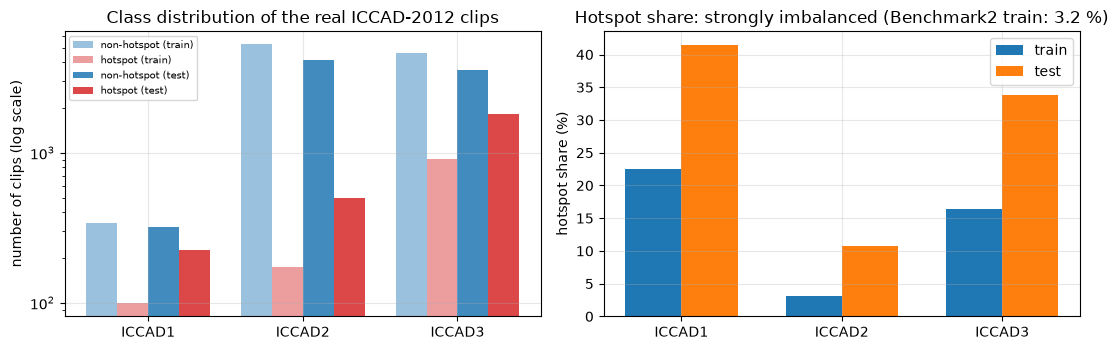

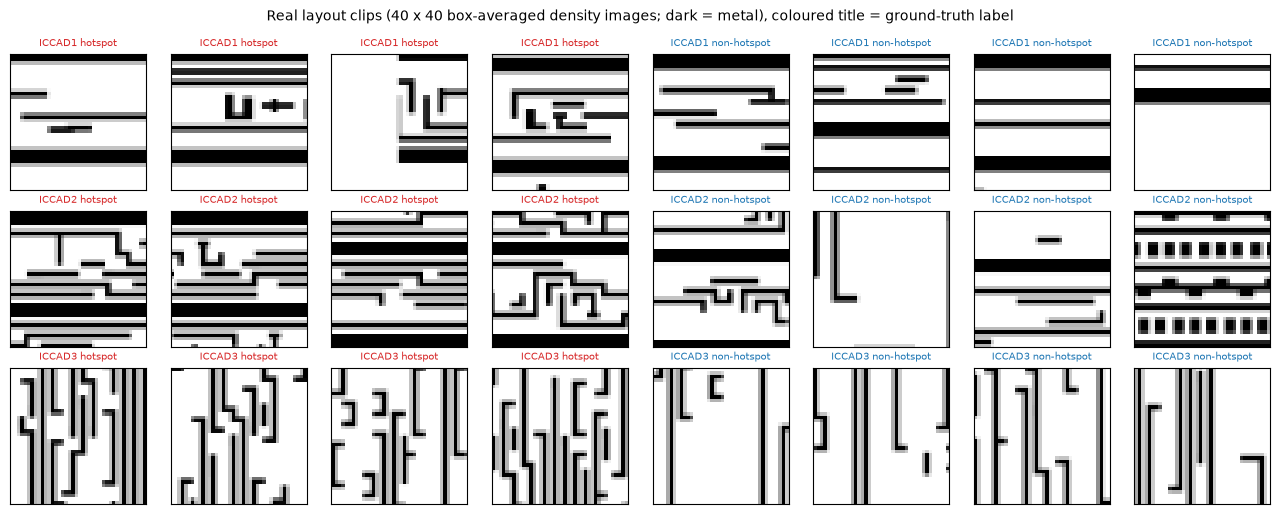

In [6]:
RAW = load_iccad(BENCHMARKS)          # RAW[bench]["train" | "test"] = (clips (n, 40, 40) uint8, labels (n,) 0 = non-hotspot, 1 = hotspot)

TABLE_I = {"ICCAD1": {"train": (99, 340), "test": (226, 319)},       # paper Table I: (hotspots, non-hotspots)
           "ICCAD2": {"train": (174, 5285), "test": (498, 4146)},
           "ICCAD3": {"train": (909, 4643), "test": (1808, 3541)}}
FEATURES = [f"px_{r}_{c}" for r in range(CLIP) for c in range(CLIP)]      # one feature per pixel of the 40 x 40 clip (pixel value 0-255 = layout density in the cell)

rows = []
for b in BENCHMARKS:
    for s in ("train", "test"):
        X, y = RAW[b][s]
        n1, n0 = int((y == 1).sum()), int((y == 0).sum())
        assert (n1, n0) == TABLE_I[b][s], (b, s, n1, n0)        # the downloaded clips reproduce the paper's Table I exactly
        rows.append(dict(benchmark=b, split=s, shape=str(X.shape), hotspots=n1, non_hotspots=n0, hotspot_share=round(n1 / (n0 + n1), 3), pixel_min=int(X.min()), pixel_max=int(X.max())))
print(f"feature names: {len(FEATURES)} pixel features, {FEATURES[:3]} ... {FEATURES[-2:]}")
print("original label values: 0 = non-hotspot (NHS), 1 = hotspot (HS); the dataset has these two classes only (no attack families)")
display(pd.DataFrame(rows))
print("counts verified against the paper's Table I: all 12 numbers identical")

# ---- class distribution of the real data (cf. paper Fig. 3) ----
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(BENCHMARKS)); wd = 0.2
for k, (s, off) in enumerate((("train", -1.5 * wd), ("test", 0.5 * wd))):
    h = [int((RAW[b][s][1] == 1).sum()) for b in BENCHMARKS]; n = [int((RAW[b][s][1] == 0).sum()) for b in BENCHMARKS]
    axs[0].bar(x + off, n, wd, color="tab:blue", alpha=0.45 + 0.4 * k, label=f"non-hotspot ({s})")
    axs[0].bar(x + off + wd, h, wd, color="tab:red", alpha=0.45 + 0.4 * k, label=f"hotspot ({s})")
axs[0].set_xticks(x + 0.0); axs[0].set_xticklabels(BENCHMARKS); axs[0].set_yscale("log"); axs[0].set_ylabel("number of clips (log scale)"); axs[0].set_title("Class distribution of the real ICCAD-2012 clips"); axs[0].legend(fontsize=7)
for k, s in enumerate(("train", "test")):
    axs[1].bar(x + (k - 0.5) * 0.35, [100 * RAW[b][s][1].mean() for b in BENCHMARKS], 0.35, label=s)
axs[1].set_xticks(x); axs[1].set_xticklabels(BENCHMARKS); axs[1].set_ylabel("hotspot share (%)"); axs[1].set_title("Hotspot share: strongly imbalanced (Benchmark2 train: 3.2 %)"); axs[1].legend()
plt.tight_layout(); plt.show()

# ---- real example clips ----
fig, axs = plt.subplots(3, 8, figsize=(13, 5.2))
rng_e = np.random.default_rng(SEED)
for i, b in enumerate(BENCHMARKS):
    X, y = RAW[b]["train"]
    for j, (lab, name) in enumerate(((1, "hotspot"), (0, "non-hotspot"))):
        for k, idx in enumerate(rng_e.choice(np.where(y == lab)[0], 4, replace=False)):
            ax = axs[i, j * 4 + k]; ax.imshow(X[idx], cmap="gray_r", vmin=0, vmax=255); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"{b} {name}", fontsize=7, color="tab:red" if lab else "tab:blue")
plt.suptitle("Real layout clips (40 x 40 box-averaged density images; dark = metal), coloured title = ground-truth label", fontsize=10); plt.tight_layout(); plt.show()


ICCAD1: train (439, 256), test (545, 256); 256 PCA components keep 100.0 % of the variance (paper: 90-99 %)
ICCAD2: train (5459, 512), test (4644, 512); 512 PCA components keep 99.3 % of the variance (paper: 90-99 %)
ICCAD3: train (5552, 512), test (5349, 512); 512 PCA components keep 99.0 % of the variance (paper: 90-99 %)


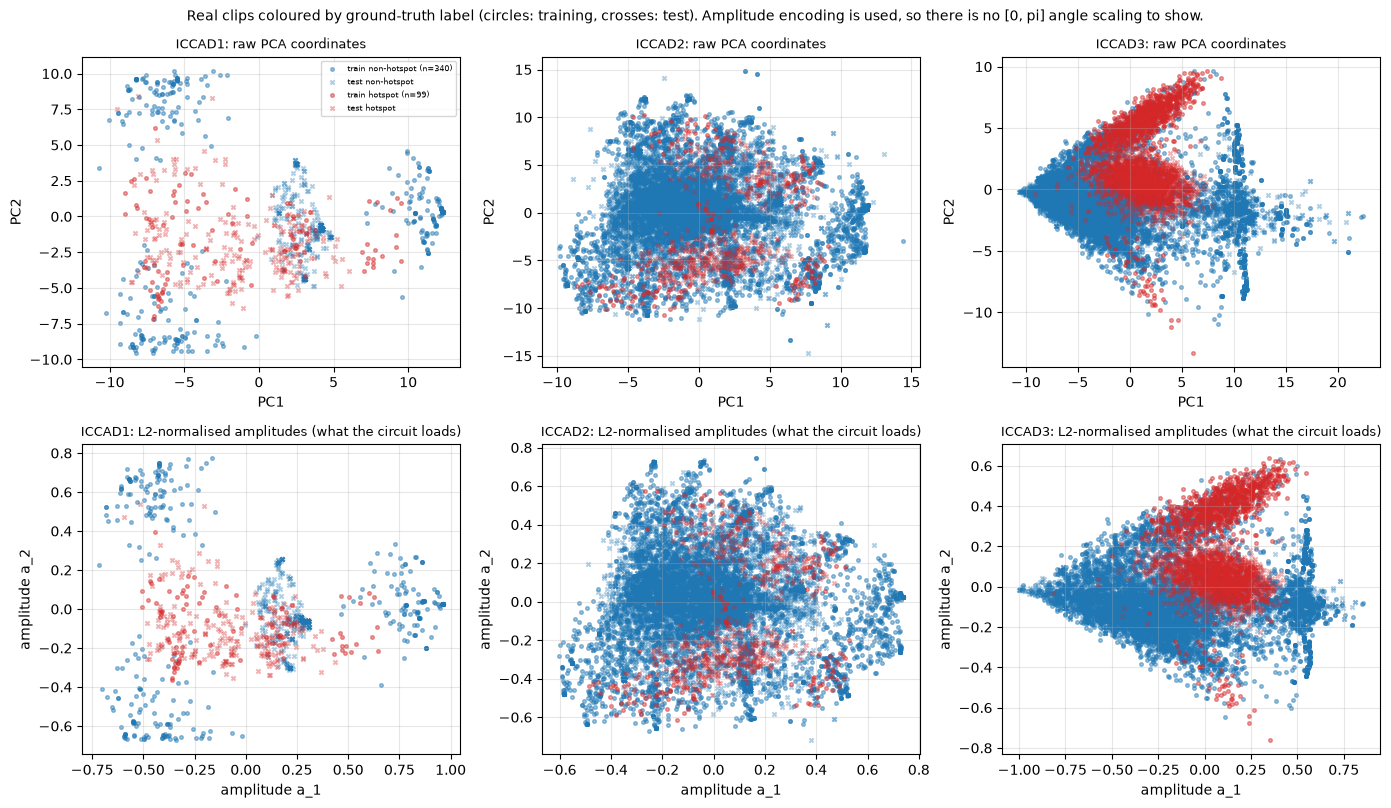

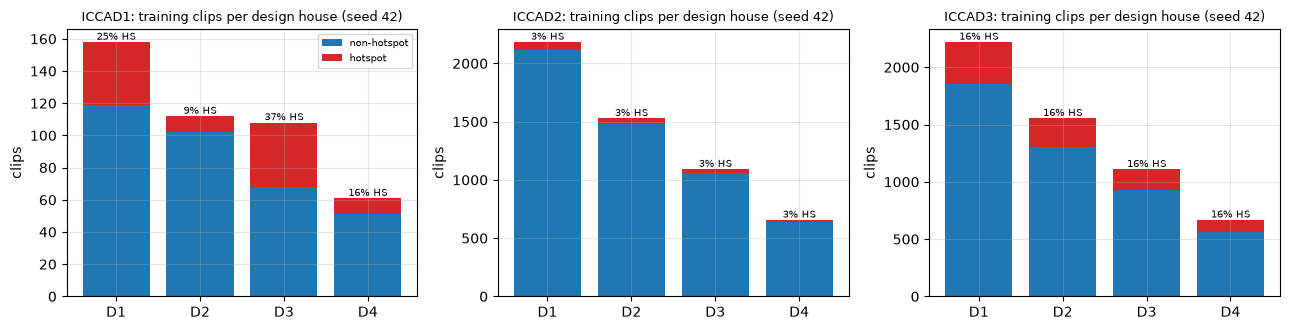

In [7]:
# PCA fitted on the training clips of each benchmark only (the test clips are projected with it).  The scatter shows REAL clips coloured by their ground-truth label.
DATA = {b: prepare(b) for b in BENCHMARKS}
for b in BENCHMARKS:
    d = DATA[b]
    print(f"{b}: train {d['Ztr'].shape}, test {d['Zte'].shape}; {N_COMP[b]} PCA components keep {100 * d['var']:.1f} % of the variance (paper: 90-99 %)")

COL = {0: "tab:blue", 1: "tab:red"}; NAME = {0: "non-hotspot", 1: "hotspot"}
fig, axs = plt.subplots(2, 3, figsize=(14, 8.2))
for i, b in enumerate(BENCHMARKS):
    d = DATA[b]
    for row, (Ztr, Zte, ttl, xl) in enumerate(((d["Ztr"], d["Zte"], "raw PCA coordinates", "PC1"), (d["Atr"], d["Ate"], "L2-normalised amplitudes (what the circuit loads)", "amplitude a_1"))):
        ax = axs[row, i]
        for lab in (0, 1):
            m = d["ytr"] == lab
            ax.scatter(Ztr[m, 0], Ztr[m, 1], s=7, c=COL[lab], alpha=0.45, label=f"train {NAME[lab]} (n={m.sum()})")
            m = d["yte"] == lab
            ax.scatter(Zte[m, 0], Zte[m, 1], s=9, c=COL[lab], marker="x", alpha=0.35, label=f"test {NAME[lab]}")
        ax.set_title(f"{b}: {ttl}", fontsize=9); ax.set_xlabel(xl); ax.set_ylabel("PC2" if row == 0 else "amplitude a_2")
        if i == 0 and row == 0: ax.legend(fontsize=6)
plt.suptitle("Real clips coloured by ground-truth label (circles: training, crosses: test). Amplitude encoding is used, so there is no [0, pi] angle scaling to show.", fontsize=10)
plt.tight_layout(); plt.show()

# ---- how the training clips are spread over the four design houses (cf. paper Fig. 5a-c) ----
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, b in zip(axs, BENCHMARKS):
    parts = partition(DATA[b]["ytr"], b, SEED)
    h = [int(DATA[b]["ytr"][p].sum()) for p in parts]; n = [len(p) - hh for p, hh in zip(parts, h)]
    ax.bar(range(4), n, color="tab:blue", label="non-hotspot"); ax.bar(range(4), h, bottom=n, color="tab:red", label="hotspot")
    ax.set_xticks(range(4)); ax.set_xticklabels([f"D{k+1}" for k in range(4)]); ax.set_title(f"{b}: training clips per design house (seed {SEED})", fontsize=9); ax.set_ylabel("clips")
    for k in range(4): ax.text(k, n[k] + h[k], f"{100*h[k]/(n[k]+h[k]):.0f}% HS", ha="center", va="bottom", fontsize=7)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()


## 3. The quantum model: a 9-qubit four-square VQC

The next cell defines the circuit twice: as a **PennyLane QNode** (the circuit that is "run") and as an **exact NumPy simulator** with an analytic gradient that is used for all training (several thousand circuit evaluations per run would be far too slow in a general-purpose
state-vector simulator). The simulator exploits that all XX gates commute: in the Hadamard basis the whole XX layer is a diagonal phase, and `H RY(t) H = RY(-t)`, so every layer is a Kronecker product of small blocks.
The simulator is then **asserted equal** to the QNode (predictions and gradient) in the circuit section below, so the results are those of the PennyLane circuit.

In [8]:
# ==========================================================================================================
# The 9-qubit four-square VQC: (1) the PennyLane QNode that DEFINES the circuit, (2) an exact NumPy simulator of
# the same circuit with an analytic gradient (back-propagation through the layers), used for all training.
# Wire 0 is the most significant bit of the state-vector index in both implementations.
# ==========================================================================================================
import pennylane as qml

N_Q, DIM = 9, 512
GRID = [[0, 1, 2], [3, 4, 5], [6, 7, 8]]                                     # Q1..Q9 on a 3 x 3 lattice (paper Fig. 4)
EDGES = [(GRID[r][c], GRID[r][c + 1]) for r in range(3) for c in range(2)] \
      + [(GRID[r][c], GRID[r + 1][c]) for r in range(2) for c in range(3)]   # the 12 sides of the four unit squares
N_E = len(EDGES)                                                             # 12 XX gates per layer
P_LAYER = N_Q + N_E                                                          # 9 RY + 12 XX = 21 parameters per layer
N_PARAMS = N_LAYERS * P_LAYER

# ------------------------------------------------------------------ (1) the PennyLane QNode (the circuit that "runs")
dev = qml.device("default.qubit", wires=N_Q)

@qml.qnode(dev)
def qnode(x, theta):
    """theta has shape (N_LAYERS, 21): per layer 9 RY angles then 12 IsingXX angles."""
    qml.AmplitudeEmbedding(x, wires=range(N_Q), pad_with=0.0, normalize=True)       # |psi> = x / ||x||  (paper Eq. 1)
    for l in range(N_LAYERS):
        for w in range(N_Q):
            qml.RY(theta[l, w], wires=w)                                             # CHOICE: single-qubit RY rotations
        for e, (a, b) in enumerate(EDGES):
            qml.IsingXX(theta[l, N_Q + e], wires=[a, b])                             # XX(phi) = exp(-i phi/2 X(x)X) on the lattice sides
    return qml.expval(qml.PauliZ(0))                                                 # readout qubit 0: P(hotspot) = (1 - <Z0>)/2

# ------------------------------------------------------------------ (2) exact simulator
# Two facts make it fast.  (a) The RY gates of a layer act on different wires: the layer is R = RY(t0) (x) ... (x) RY(t8) (real).
# (b) All XX gates commute and are diagonal in the Hadamard (X) basis: prod_e XX_e(phi_e) = H D H with H = (1/sqrt 2 [[1,1],[1,-1]])^(x)9 and
#     D = diag(exp(-i/2 sum_e phi_e s_a(j) s_b(j))), s_w(j) = +-1 the value of bit w of the Hadamard-basis index j.
# Moreover H RY(t) H = RY(-t), so the whole circuit is  H D_L R_L^X D_{L-1} ... R_2^X D_1 H R_1 |psi>  with R^X the RY layer with negated angles:
# one RY layer and one Hadamard layer in front, then (RY layer, diagonal phase) pairs, and one Hadamard layer at the end.  Every layer operator
# is a Kronecker product of small blocks, applied with a few small contractions; the gradient is back-propagated exactly through the same stages.
_H1 = np.array([[1.0, 1.0], [1.0, -1.0]]) / np.sqrt(2)
def _hk(n):
    H = np.array([[1.0]])
    for _ in range(n):
        H = np.kron(H, _H1)
    return H
HF9 = (_hk(3), _hk(3), _hk(3))                       # Hadamard on 9 qubits as three 8 x 8 blocks
HF8 = (_hk(2), _hk(3), _hk(3))                       # Hadamard on 8 qubits (4 x 8 x 8), for the half-size final step
_j = np.arange(DIM)
SGN = np.stack([1 - 2 * ((_j >> (N_Q - 1 - w)) & 1) for w in range(N_Q)]).astype(float)       # (9, 512): s_w(j)
PERM_BIT = np.stack([_j ^ (1 << (N_Q - 1 - w)) for w in range(N_Q)])                   # (9, 512): index with bit w flipped
ZE = np.stack([SGN[a] * SGN[b] for a, b in EDGES])                                   # (12, 512): eigenvalues of X_a X_b in the Hadamard basis

def _y_grad(M):
    """M[i, j] = sum_b gb_b Re(conj(lam_b[i]) phi_b[j]); returns, for every qubit w, sum_j s_w(j) M[j ^ bit_w, j]  (= sum_b gb_b Im<lam_b| Y_w phi_b>)"""
    return np.array([(SGN[w] * M[PERM_BIT[w], _j]).sum() for w in range(N_Q)])

def _ry_factors(t, sign=1.0):
    """the RY layer RY(s t0) (x) ... (x) RY(s t8) as three 8 x 8 blocks (qubits 0-2, 3-5, 6-8)"""
    ry = lambda a: np.array([[np.cos(a / 2), -np.sin(a / 2)], [np.sin(a / 2), np.cos(a / 2)]])
    return tuple(np.kron(ry(sign * t[3 * g]), np.kron(ry(sign * t[3 * g + 1]), ry(sign * t[3 * g + 2]))) for g in range(3))

def _ap(x, F):
    """apply F[0] (x) F[1] (x) F[2] (small blocks of sizes a, b, c) to every row of x (n, a*b*c) with three small contractions"""
    n = x.shape[0]; a, b, c = (f.shape[0] for f in F)
    t = np.matmul(F[0], x.reshape(n, a, b * c))
    t = np.matmul(F[1], t.reshape(n * a, b, c))
    return (t.reshape(-1, c) @ F[2].T).reshape(n, a * b * c)

def _apc(re, im, F):
    """apply a real operator to a complex batch with one stacked call"""
    B = re.shape[0]
    out = _ap(np.concatenate([re, im], axis=0), F)
    return out[:B], out[B:]

def prep_states(Xamp):
    """amplitude embedding of already L2-normalised real vectors, zero padded to 512 amplitudes (real array (B, 512))"""
    S = np.zeros((Xamp.shape[0], DIM)); S[:, :Xamp.shape[1]] = Xamp
    return S

def _forward(theta, S):
    """returns (state after the last phase layer in the Hadamard basis, list of stage records, the real state after the first RY layer)"""
    th = theta.reshape(N_LAYERS, P_LAYER)
    s1 = _ap(S, _ry_factors(th[0, :N_Q]))                  # first RY layer (real)
    xr = _ap(s1, HF9); xi = np.zeros_like(xr)             # to the Hadamard basis (real)
    recs = []
    for l in range(N_LAYERS):
        RX = None
        if l > 0:
            RX = _ry_factors(th[l, :N_Q], -1.0)           # RY layer seen from the Hadamard basis
            xr, xi = _apc(xr, xi, RX)
        pre = (xr, xi)                                     # state before the phase layer (after the RY layer)
        ph = -0.5 * (th[l, N_Q:] @ ZE)                     # D = exp(i ph)
        c, s = np.cos(ph), np.sin(ph)
        xr, xi = xr * c - xi * s, xr * s + xi * c
        recs.append((RX, pre, c, s, xr, xi))
    return xr, xi, recs, s1

def _top_half_out(xr, xi):
    """amplitudes of the output state |psi_out> = H x on the qubit-0 = 1 half:  (1/sqrt 2) H_8 (x[top=0] - x[top=1])"""
    dr, di = (xr[:, :DIM // 2] - xr[:, DIM // 2:]) / np.sqrt(2), (xi[:, :DIM // 2] - xi[:, DIM // 2:]) / np.sqrt(2)
    return _apc(dr, di, HF8)

def forward_p(theta, S):
    xr, xi, _, _ = _forward(theta, S)
    ar, ai = _top_half_out(xr, xi)
    return np.sum(ar * ar + ai * ai, axis=1)

def predict_p(theta, S):
    """P(hotspot) for many inputs: propagate the d basis states once to get the circuit unitary, then one product"""
    d = S.shape[1]
    xr, xi, _, _ = _forward(theta, np.eye(DIM)[:d])
    ar, ai = _top_half_out(xr, xi)                         # row i: amplitudes of the qubit-0 = 1 half for the input basis state i
    a, b = S[:, :d] @ ar, S[:, :d] @ ai
    return np.sum(a * a + b * b, axis=1)

def loss_and_grad(theta, S, y, wcls):
    """class-weighted binary cross-entropy of sigmoid(KAPPA (2 p - 1)), p = P(hotspot) = <(1 - |0><0|)_q0>, and its exact gradient w.r.t. theta"""
    B = S.shape[0]
    xr, xi, recs, s1 = _forward(theta, S)
    ar, ai = _top_half_out(xr, xi)
    p = np.sum(ar * ar + ai * ai, axis=1)
    z = KAPPA * (2 * p - 1)                                # logit = KAPPA * (-<Z_0>);  y_hat = sigmoid(z);  y_hat >= 0.5  <=>  P(hotspot) >= 0.5
    wt = np.where(y == 1, wcls[1], wcls[0])
    loss = np.mean(wt * (np.logaddexp(0.0, z) - y * z))    # weighted binary cross-entropy
    gb = wt * (1 / (1 + np.exp(-z)) - y) * 2 * KAPPA / B   # d loss / d P(hotspot)
    # adjoint at the output of the last phase layer: lam = H (O psi_out), O psi_out = psi_out on the top half, 0 elsewhere
    hr, hi = _apc(ar, ai, HF8)                             # H_8 (psi_out top half) ; lam_top0 = hr/sqrt2, lam_top1 = -hr/sqrt2
    lr_ = np.concatenate([hr, -hr], axis=1) / np.sqrt(2); li_ = np.concatenate([hi, -hi], axis=1) / np.sqrt(2)
    grad = np.zeros((N_LAYERS, P_LAYER))
    for l in reversed(range(N_LAYERS)):
        RX, (pr, pi), c, s, qr, qi = recs[l]
        # --- XX angles: generator z_e (diagonal) on the state after the phase layer; dp/dphi_e = Im<lam| z_e phi>
        q = (gb[:, None] * (lr_ * qi - li_ * qr)).sum(0)
        grad[l, N_Q:] = ZE @ q
        lr_, li_ = lr_ * c + li_ * s, li_ * c - lr_ * s    # lam before the phase layer = conj(D) lam
        if l > 0:
            # --- RY angles of layer l+1 seen from the Hadamard basis: gate RY(-t) = exp(+i t Y / 2), generator -Y_w on the state (pr, pi)
            grad[l, :N_Q] = -_y_grad((gb[:, None] * lr_).T @ pr + (gb[:, None] * li_).T @ pi)
            lr_, li_ = _apc(lr_, li_, tuple(f.T for f in RX))   # lam before the RY layer = R^T lam
        else:
            # --- RY angles of the first layer: state s1 is real, so only the real part of lam in the computational basis matters
            lam_s = _ap(lr_, HF9)
            grad[0, :N_Q] = _y_grad((gb[:, None] * lam_s).T @ s1)
    return loss, grad.ravel(), p


## Quantum Circuit Architecture

The circuit that is actually executed is drawn from the real QNode (`qml.draw_mpl`): amplitude embedding of a real test clip, then per layer a column of `RY` rotations and the 12 `IsingXX` gates on the sides of the 3 x 3 lattice of the paper's Fig. 4, then the read-out of qubit 0.
The paper omits the circuit details (single-qubit gates, number of layers, read-out qubit); each assumption is documented in the table at the top and printed below. Qubit count, depth and number of trainable parameters are printed; the same cell asserts that the simulator used for training
reproduces the QNode's output on real clips and its gradient (compared with PennyLane's own autograd gradient and with finite differences).

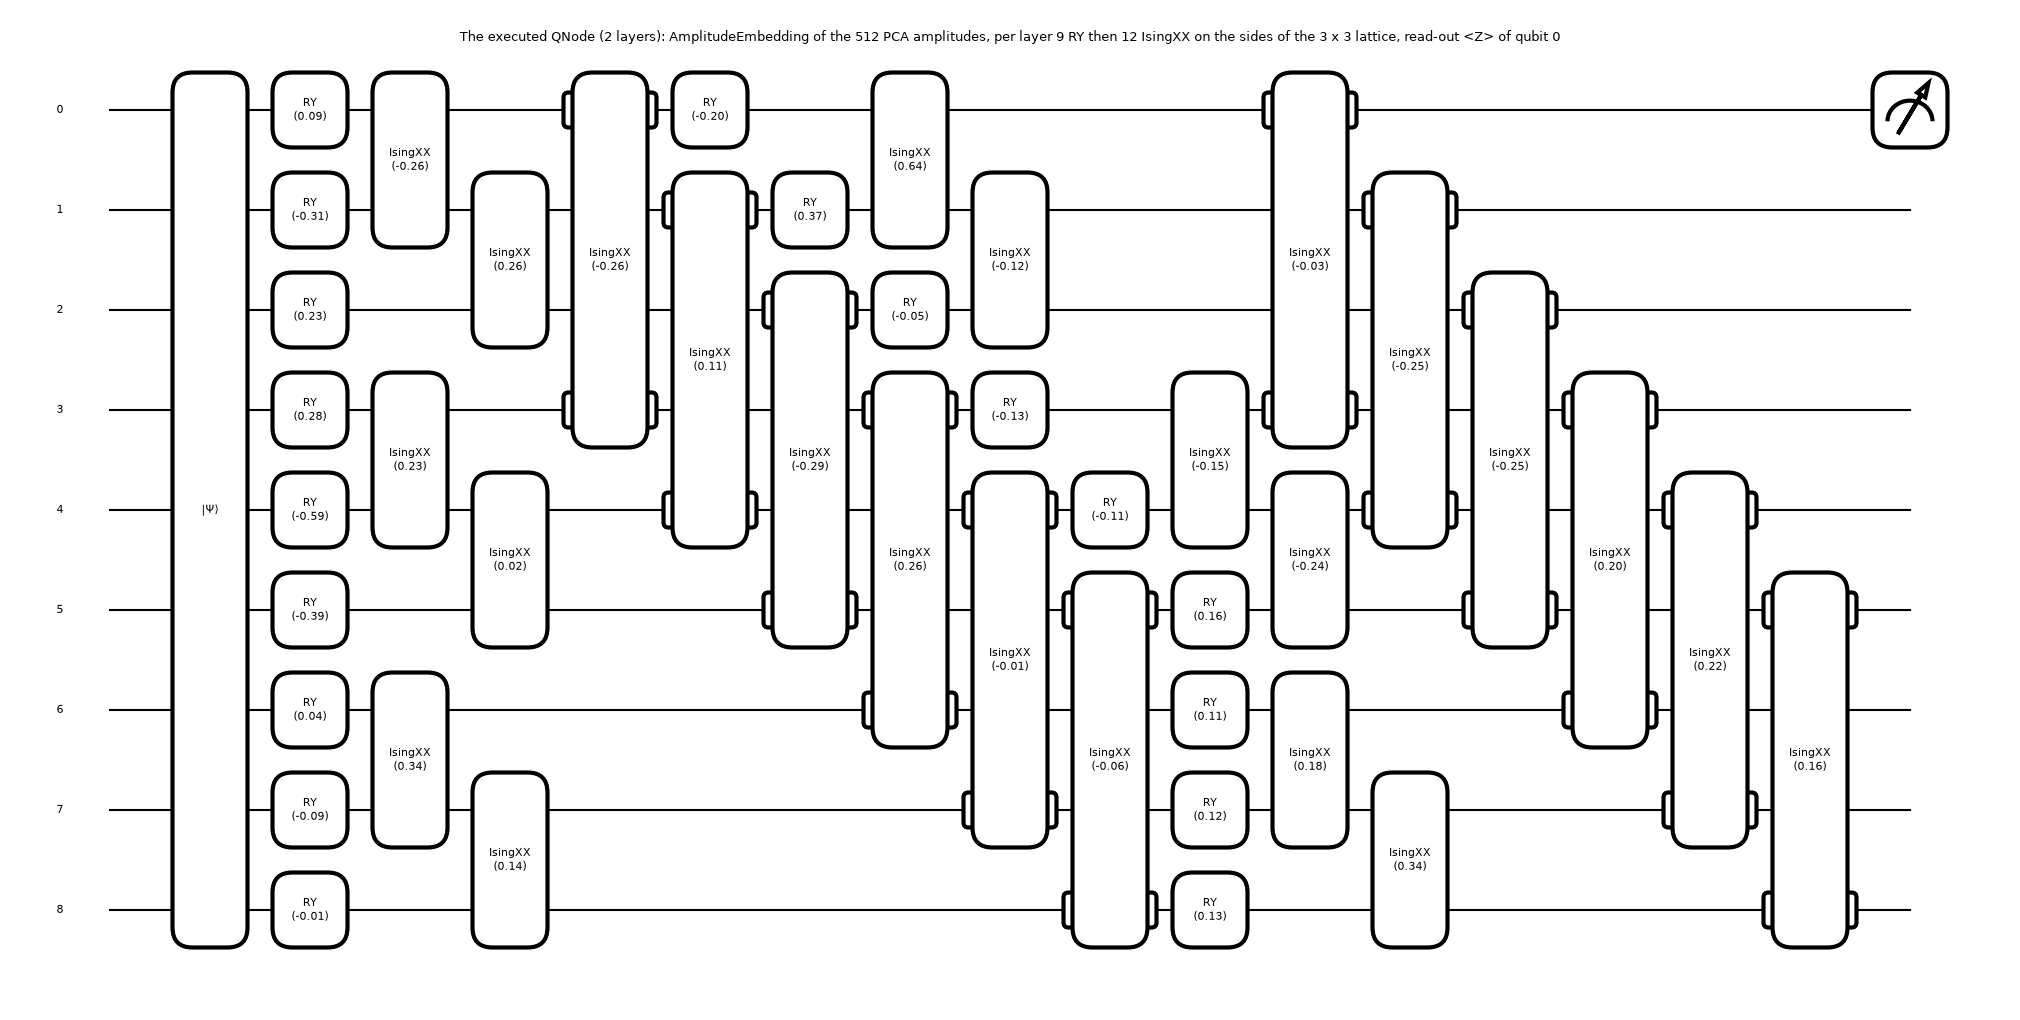

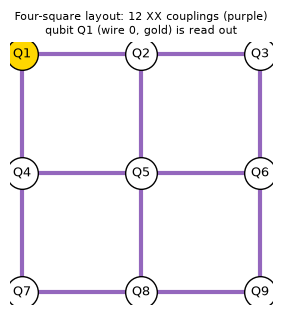

qubits: 9 (2^9 = 512 amplitudes = the 512 PCA components; Benchmark1 uses 256 components padded with zeros)
trainable parameters: 42 = 2 layers x (9 RY + 12 XX angles)   (the 512 input amplitudes are data, not parameters)
circuit depth of the variational part alone: 10 (42 gates);  QNode with the amplitude embedding as one block: depth 11;  with the exact state preparation written out as RY/RZ/CNOT gates (what hardware would need): depth 2003 (2051 gates)
measurement: <Z> of qubit 0, P(hotspot) = (1 - <Z_0>)/2 = <(1 - |0><0|)_0>, i.e. the observable O_f = 1 - |0><0| of the paper's Eq. 4 restricted to the read-out qubit
assumptions (the paper omits them): RY single-qubit layer before each XX layer (without it the XX layers commute and the model would collapse to one effective layer), layer count, read-out qubit and loss; see the table at the top


simulator vs PennyLane QNode, P(hotspot) on 75 real test clips (3 benchmarks) with random angles: max |difference| = 2.2e-15  (assert < 1e-10: passed)


gradient of the simulator vs PennyLane autograd: max |diff| = 3.0e-14;  vs finite differences: 1.0e-09;  (largest component 7.372)
analytic gradient asserted equal to PennyLane's gradient and to finite differences (assert passed)


In [9]:
# ---- the circuit that is executed: the real PennyLane QNode (amplitude embedding of a real test clip, N_LAYERS blocks of RY layer + XX layer, <Z_0> read-out) ----
from pennylane import numpy as pnp
x_demo = DATA["ICCAD3"]["Ate"][0]
th_demo = np.random.default_rng(SEED).normal(0, INIT_STD, (N_LAYERS, P_LAYER))

fig, ax = qml.draw_mpl(qnode, level="top", decimals=2, fontsize=8)(x_demo, th_demo)
fig.suptitle(f"The executed QNode ({N_LAYERS} layers): AmplitudeEmbedding of the 512 PCA amplitudes, per layer 9 RY then 12 IsingXX on the sides of the 3 x 3 lattice, read-out <Z> of qubit 0", fontsize=9)
plt.show()

# the 3 x 3 four-square layout of Fig. 4: which qubit pairs carry an XX gate
fig, ax = plt.subplots(figsize=(3.6, 3.4))
pos = {GRID[r][c]: (c, 2 - r) for r in range(3) for c in range(3)}
for a, b in EDGES: ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], "-", color="tab:purple", lw=3, zorder=1)
for q, (xx, yy) in pos.items():
    ax.scatter(xx, yy, s=520, c="white" if q else "gold", edgecolor="k", zorder=2); ax.text(xx, yy, f"Q{q+1}", ha="center", va="center", fontsize=9, zorder=3)
ax.set_title("Four-square layout: 12 XX couplings (purple)\nqubit Q1 (wire 0, gold) is read out", fontsize=8); ax.axis("off"); ax.set_aspect("equal"); plt.show()

sp_top = qml.specs(qnode, level="top")(x_demo, th_demo).resources
@qml.qnode(dev)
def _qnode_gates(x, t):                                   # the same circuit with the amplitude embedding written out as gates (Mottonen decomposition)
    qml.MottonenStatePreparation(x, wires=range(N_Q))
    for l in range(N_LAYERS):
        for w in range(N_Q): qml.RY(t[l, w], wires=w)
        for e, (a, b) in enumerate(EDGES): qml.IsingXX(t[l, N_Q + e], wires=[a, b])
    return qml.expval(qml.PauliZ(0))
_qg = qml.transforms.decompose(_qnode_gates, gate_set={"RY", "RZ", "CNOT", "IsingXX", "GlobalPhase"})
sp_dev = qml.specs(_qg, level="device")(x_demo, th_demo).resources
assert abs(float(_qg(x_demo, th_demo)) - float(qnode(x_demo, th_demo))) < 1e-10      # gate-level state preparation gives the same expectation value
@qml.qnode(dev)
def _ansatz_only(t):
    for l in range(N_LAYERS):
        for w in range(N_Q): qml.RY(t[l, w], wires=w)
        for e, (a, b) in enumerate(EDGES): qml.IsingXX(t[l, N_Q + e], wires=[a, b])
    return qml.expval(qml.PauliZ(0))
sp_var = qml.specs(_ansatz_only, level="device")(th_demo).resources
print(f"qubits: {N_Q} (2^{N_Q} = {DIM} amplitudes = the 512 PCA components; Benchmark1 uses 256 components padded with zeros)")
print(f"trainable parameters: {N_PARAMS} = {N_LAYERS} layers x ({N_Q} RY + {N_E} XX angles)   (the 512 input amplitudes are data, not parameters)")
print(f"circuit depth of the variational part alone: {sp_var.depth} ({sp_var.num_gates} gates);  QNode with the amplitude embedding as one block: depth {sp_top.depth};  with the exact state preparation written out as RY/RZ/CNOT gates (what hardware would need): depth {sp_dev.depth} ({sp_dev.num_gates} gates)")
print("measurement: <Z> of qubit 0, P(hotspot) = (1 - <Z_0>)/2 = <(1 - |0><0|)_0>, i.e. the observable O_f = 1 - |0><0| of the paper's Eq. 4 restricted to the read-out qubit")
print("assumptions (the paper omits them): RY single-qubit layer before each XX layer (without it the XX layers commute and the model would collapse to one effective layer), layer count, read-out qubit and loss; see the table at the top")

# ---- the exact NumPy simulator used for all training is the SAME circuit: assert it against the QNode on real clips and check the gradient three ways ----
rng = np.random.default_rng(SEED); max_dev = 0.0
for b in BENCHMARKS:
    A = DATA[b]["Ate"][:25]; th = rng.normal(0, 1.0, (N_LAYERS, P_LAYER))
    ref = np.array([(1 - qnode(a, th)) / 2 for a in A])
    p_sim = predict_p(th.ravel(), prep_states(A)); p_fwd = forward_p(th.ravel(), prep_states(A))
    max_dev = max(max_dev, float(np.abs(p_sim - ref).max()), float(np.abs(p_fwd - ref).max()))
assert max_dev < 1e-10, max_dev
print(f"simulator vs PennyLane QNode, P(hotspot) on 75 real test clips (3 benchmarks) with random angles: max |difference| = {max_dev:.1e}  (assert < 1e-10: passed)")

A = DATA["ICCAD2"]["Atr"][:12]; yb = DATA["ICCAD2"]["ytr"][:12].copy(); yb[:4] = 1; wc = (0.6, 1.7); th = rng.normal(0, 0.7, N_PARAMS)
loss, g, _ = loss_and_grad(th, prep_states(A), yb, wc)
# (1) PennyLane autograd (back-propagation through the QNode) of the same weighted cross-entropy of sigmoid(KAPPA (2P - 1))
def pl_loss(t):
    p = pnp.stack([(1 - qnode(a, t.reshape(N_LAYERS, P_LAYER))) / 2 for a in A])
    z = KAPPA * (2 * p - 1)
    w = pnp.where(yb == 1, wc[1], wc[0])
    return pnp.mean(w * (pnp.log(1 + pnp.exp(z)) - yb * z))
g_pl = qml.grad(pl_loss)(pnp.array(th, requires_grad=True))
# (2) central finite differences of the simulator
g_fd = np.array([(loss_and_grad(th + h, prep_states(A), yb, wc)[0] - loss_and_grad(th - h, prep_states(A), yb, wc)[0]) / 2e-6 for h in np.eye(N_PARAMS) * 1e-6])
print(f"gradient of the simulator vs PennyLane autograd: max |diff| = {np.abs(g - g_pl).max():.1e};  vs finite differences: {np.abs(g - g_fd).max():.1e};  (largest component {np.abs(g).max():.3f})")
assert np.abs(g - g_pl).max() < 1e-8 and np.abs(g - g_fd).max() < 1e-6
print("analytic gradient asserted equal to PennyLane's gradient and to finite differences (assert passed)")


### 3b. Choosing the local learning rate on a validation split

The paper gives no learning rate. Four houses train for a few rounds on 80 % of the **training** clips of Benchmark3 (clean labels) and the other 20 % of the training clips (stratified) score the global model. The test set is not used.

In [10]:
# Local learning rate: chosen on a validation split of the TRAINING data of Benchmark3 (clean labels, never the test set).  Four houses train on 80 % of the
# training clips, the other 20 % (stratified) score the global model; criterion = balanced accuracy (mean of TPR and 1 - FPR) averaged over the last two evaluations.
from sklearn.model_selection import train_test_split
VAL_ROUNDS = 10 if FAST_MODE else 30
d3 = DATA["ICCAD3"]
i_tr, i_va = train_test_split(np.arange(len(d3["ytr"])), test_size=0.2, stratify=d3["ytr"], random_state=SEED)
dval = dict(Atr=d3["Atr"][i_tr], ytr=d3["ytr"][i_tr], Ate=d3["Atr"][i_va], yte=d3["ytr"][i_va])
val_rows = []
for lr_ in LR_GRID:
    o = run_fed(QuantumModel(), dval, "ICCAD3", SEED, VAL_ROUNDS, lr=lr_, eval_every=max(1, VAL_ROUNDS // 5))
    bal = np.mean([(h["tpr"] + 1 - h["fpr"]) / 2 for h in o["hist"][-2:]])
    val_rows.append(dict(lr=lr_, balanced_accuracy_val=round(float(bal), 4), accuracy_val=round(float(np.mean([h["acc"] for h in o["hist"][-2:]])), 4), val_loss=round(float(o["hist"][-1]["loss"]), 4)))
display(pd.DataFrame(val_rows))
LR = max(val_rows, key=lambda r: r["balanced_accuracy_val"])["lr"]
print("selected local learning rate LR =", LR, "(used for the quantum model and for the classical twin in all later sections)")


,lr,balanced_accuracy_val,accuracy_val,val_loss
0,0.02,0.6025,0.6899,0.5568
1,0.05,0.7446,0.7705,0.4563
2,0.10,0.7462,0.8047,0.4288


selected local learning rate LR = 0.1 (used for the quantum model and for the classical twin in all later sections)


## 4. Without attack (paper Section IV-B, Fig. 5)

Four houses, non-IID data, `ROUNDS` communication rounds. The first figure is Fig. 5 (d-f): the test loss of the global model and of each house's model right after its local training. The next figures are the box plots over seeds (g-i) and the confusion matrices (j-l).

In [11]:
# ---------------------------------------------------------------- bookkeeping shared by sections 4-7
RES = {}                       # (model kind, benchmark, scenario, seed) -> output of run_fed
EPS = {}                       # defence threshold per (benchmark, variant), calibrated in section 6
KINDS = {"q": "FedVQC (quantum)", "c": "FedLogReg (classical twin)"}

def get_model(kind, bench):
    return QuantumModel() if kind == "q" else LogisticModel(DATA[bench]["Atr"].shape[1])

def mal_set(seed, F):
    """which of the four houses are malicious: the first F of one fixed random permutation per seed (nested across F)"""
    return tuple(sorted(int(i) for i in np.random.default_rng(seed + 5).permutation(N_CLIENTS)[:F]))

def do_run(kind, bench, scen, seed, F=0, rate=FLIP_RATE, defence=None, track=False):
    key = (kind, bench, scen, seed)
    if key in RES:
        return RES[key]
    t0 = time.time()
    out = run_fed(get_model(kind, bench), DATA[bench], bench, seed, ROUNDS, malicious=mal_set(seed, F) if F else (), flip_rate=rate,
                  defence=defence, track_local=track)
    out["time"] = time.time() - t0
    RES[key] = out
    f = final_metrics(out)
    print(f"  [{kind}] {bench} {scen:<10s} seed {seed}  malicious={out['malicious']}  acc {100*f['acc']:5.1f}  F1 {100*f['f1']:5.1f}  TPR {100*f['tpr']:5.1f}  FPR {100*f['fpr']:5.1f}   ({out['time']:.0f} s)", flush=True)
    return out

def final_metrics(out, k=3):
    """scalar metrics = mean over the last k evaluations of the global model (damps the round-to-round oscillation); confusion matrix = last evaluation"""
    rows = out["hist"][-k:]
    m = {key: float(np.mean([r[key] for r in rows])) for key in ("acc", "prec", "rec", "f1", "wf1", "tpr", "fpr", "loss")}
    m.update({key: out["hist"][-1][key] for key in ("tn", "fp", "fn", "tp")})
    return m

def agg(kind, bench, scen, key):
    """(mean, std) over the seeds of one final metric, in percent"""
    v = [100 * final_metrics(RES[(kind, bench, scen, s)])[key] for s in SEEDS if (kind, bench, scen, s) in RES]
    return (float(np.mean(v)), float(np.std(v))) if v else (np.nan, np.nan)

def pm(kind, bench, scen, key):
    m, s = agg(kind, bench, scen, key)
    return f"{m:5.1f} +- {s:4.1f}" if len(SEEDS) > 1 else f"{m:5.1f}"

def conf_pct(out):
    h = out["hist"][-1]
    return np.array([[h["tn"], h["fp"]], [h["fn"], h["tp"]]], float) / np.array([[h["tn"] + h["fp"]], [h["fn"] + h["tp"]]])

def draw_conf(ax, out, title):
    cm = conf_pct(out)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{100*cm[i, j]:.0f}%", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["non-hotspot", "hotspot"], fontsize=7); ax.set_yticks([0, 1]); ax.set_yticklabels(["non-hotspot", "hotspot"], fontsize=7)
    ax.set_xlabel("predicted", fontsize=8); ax.set_ylabel("true", fontsize=8); ax.set_title(title, fontsize=9); ax.grid(False)

def metric_table(kind, scen, keys=("acc", "prec", "rec", "f1", "wf1", "fpr")):
    names = {"acc": "accuracy %", "prec": "precision %", "rec": "recall (TPR) %", "f1": "F1 (hotspot) %", "wf1": "weighted F1 %", "fpr": "FPR %"}
    return pd.DataFrame({names[k]: {b: pm(kind, b, scen, k) for b in BENCHMARKS} for k in keys})


FedVQC without attack: 100 rounds, 2 seed(s), 3 benchmarks


  [q] ICCAD1 clean      seed 42  malicious=()  acc  41.1  F1  58.2  TPR  99.0  FPR  99.9   (124 s)


  [q] ICCAD1 clean      seed 43  malicious=()  acc  41.9  F1  58.7  TPR  99.6  FPR  99.0   (97 s)


  [q] ICCAD2 clean      seed 42  malicious=()  acc  76.7  F1  15.4  TPR  20.7  FPR  16.6   (129 s)


  [q] ICCAD2 clean      seed 43  malicious=()  acc  81.1  F1   5.4  TPR   6.4  FPR   9.9   (109 s)


  [q] ICCAD3 clean      seed 42  malicious=()  acc  70.0  F1  39.7  TPR  31.1  FPR  10.2   (160 s)


  [q] ICCAD3 clean      seed 43  malicious=()  acc  74.4  F1  53.2  TPR  43.2  FPR   9.6   (97 s)


,accuracy %,precision %,recall (TPR) %,F1 (hotspot) %,weighted F1 %,FPR %
mean +- std over seeds,,,,,,
ICCAD1,41.5 +- 0.4,41.4 +- 0.2,99.3 +- 0.3,58.5 +- 0.2,24.9 +- 0.6,99.4 +- 0.5
ICCAD2,78.9 +- 2.2,10.0 +- 2.7,13.6 +- 7.1,10.4 +- 5.0,79.6 +- 0.8,13.2 +- 3.4
ICCAD3,72.2 +- 2.2,64.7 +- 4.9,37.2 +- 6.0,46.5 +- 6.7,69.4 +- 3.1,9.9 +- 0.3


,ICCAD1,ICCAD2,ICCAD3
training+evaluation time of one run (s),110.8,118.8,128.5


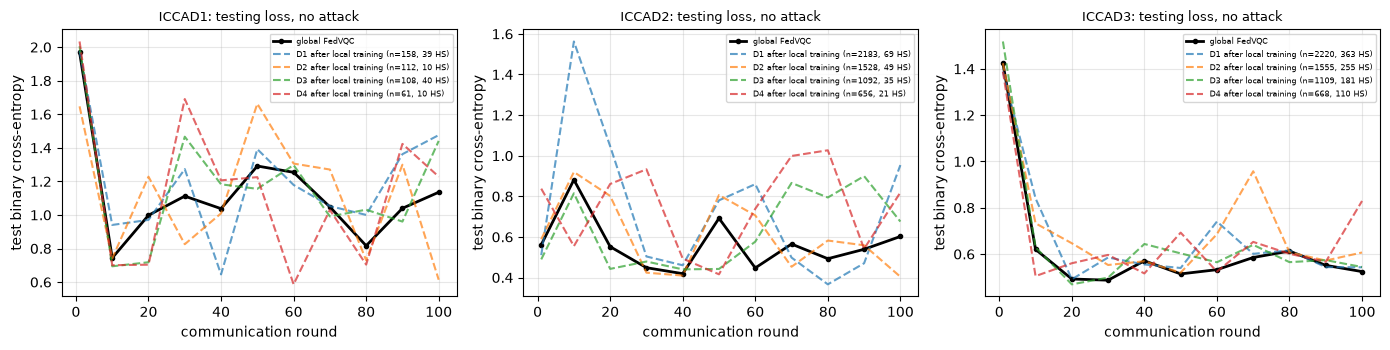

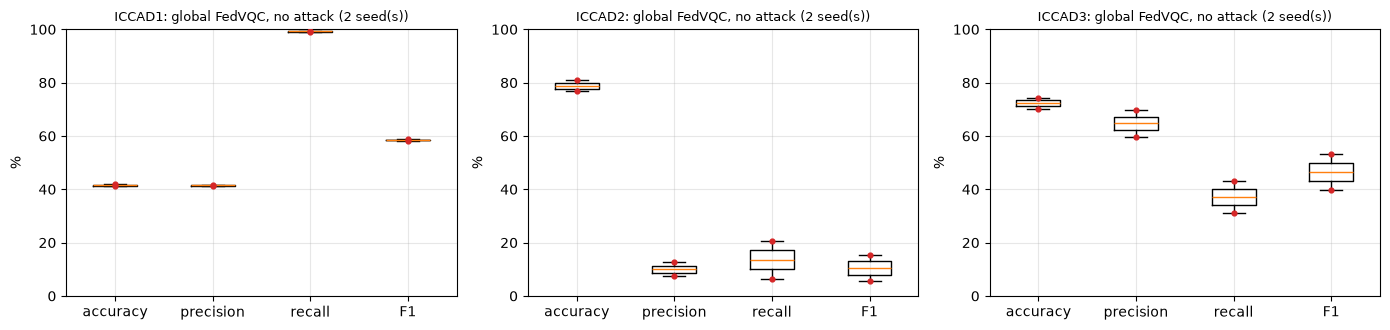

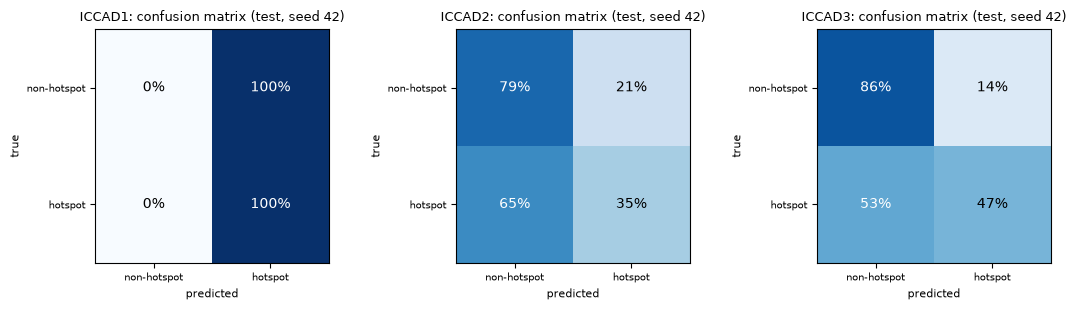

In [12]:
print(f"FedVQC without attack: {ROUNDS} rounds, {len(SEEDS)} seed(s), {len(BENCHMARKS)} benchmarks")
for b in BENCHMARKS:
    for sd in SEEDS:
        do_run("q", b, "clean", sd, track=(sd == SEEDS[0]))

display(metric_table("q", "clean").rename_axis("mean +- std over seeds"))
tt = pd.DataFrame({b: {"training+evaluation time of one run (s)": np.mean([RES[("q", b, "clean", s)]["time"] for s in SEEDS])} for b in BENCHMARKS})
display(tt.round(1))

# ---- cf. paper Fig. 5 (d-f): convergence of the testing loss of the global model and of the four local models after their local training ----
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, b in zip(axs, BENCHMARKS):
    o = RES[("q", b, "clean", SEEDS[0])]; rr = [h["round"] for h in o["hist"]]
    ax.plot(rr, [h["loss"] for h in o["hist"]], "k-o", lw=2, ms=3, label="global FedVQC")
    for c in range(N_CLIENTS):
        ax.plot(rr, [h["local_loss"][c] for h in o["hist"]], "--", alpha=0.7, label=f"D{c+1} after local training (n={o['sizes'][c]}, {o['hs'][c]} HS)")
    ax.set_xlabel("communication round"); ax.set_ylabel("test binary cross-entropy"); ax.set_title(f"{b}: testing loss, no attack", fontsize=9); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

# ---- cf. Fig. 5 (g-i): box plots over the seeds of the metrics of the global model;  (j-l): confusion matrices ----
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, b in zip(axs, BENCHMARKS):
    keys = ("acc", "prec", "rec", "f1")
    data = [[100 * final_metrics(RES[("q", b, "clean", s)])[k] for s in SEEDS] for k in keys]
    ax.boxplot(data, tick_labels=["accuracy", "precision", "recall", "F1"]);
    for i, d in enumerate(data): ax.scatter(np.full(len(d), i + 1), d, c="tab:red", s=12, zorder=3)
    ax.set_ylim(0, 100); ax.set_title(f"{b}: global FedVQC, no attack ({len(SEEDS)} seed(s))", fontsize=9); ax.set_ylabel("%")
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, b in zip(axs, BENCHMARKS):
    draw_conf(ax, RES[("q", b, "clean", SEEDS[0])], f"{b}: confusion matrix (test, seed {SEEDS[0]})")
plt.tight_layout(); plt.show()


## 5. With label flipping (paper Section IV-C, Fig. 6)

`F` of the 4 houses flip all their labels. Which houses are malicious is a fixed random permutation per seed (nested across `F`). Figures: accuracy during training (a-c), box plots of accuracy / precision / recall / F1 per attack proportion (d-f), confusion matrices for 50 % malicious houses (g-i).

FedVQC with label flipping: F in [1, 2, 3] malicious houses out of 4, flip rate 1.0


  [q] ICCAD1 F1         seed 42  malicious=(0,)  acc  27.0  F1  41.9  TPR  64.7  FPR  99.7   (113 s)


  [q] ICCAD1 F1         seed 43  malicious=(3,)  acc  39.9  F1  55.5  TPR  90.9  FPR  96.2   (120 s)


  [q] ICCAD2 F1         seed 42  malicious=(0,)  acc  61.8  F1  22.5  TPR  46.6  FPR  36.4   (122 s)


  [q] ICCAD2 F1         seed 43  malicious=(3,)  acc  70.4  F1  12.2  TPR  27.2  FPR  24.4   (127 s)


...

FPR %


,no attack,F=1 (25 %),F=2 (50 %),F=3 (75 %)
ICCAD1,99.4 +- 0.5,98.0 +- 1.7,46.1 +- 7.3,31.7 +- 31.6
ICCAD2,13.2 +- 3.4,30.4 +- 6.0,43.5 +- 19.8,69.0 +- 2.9
ICCAD3,9.9 +- 0.3,13.8 +- 3.0,23.5 +- 7.4,87.4 +- 1.6


accuracy % of F = 2 houses that flip only a fraction q of their labels (seed

 42 )


,q=0.25,q=1.0
ICCAD1,38.5,53.7
ICCAD2,49.8,38.8
ICCAD3,74.5,57.4


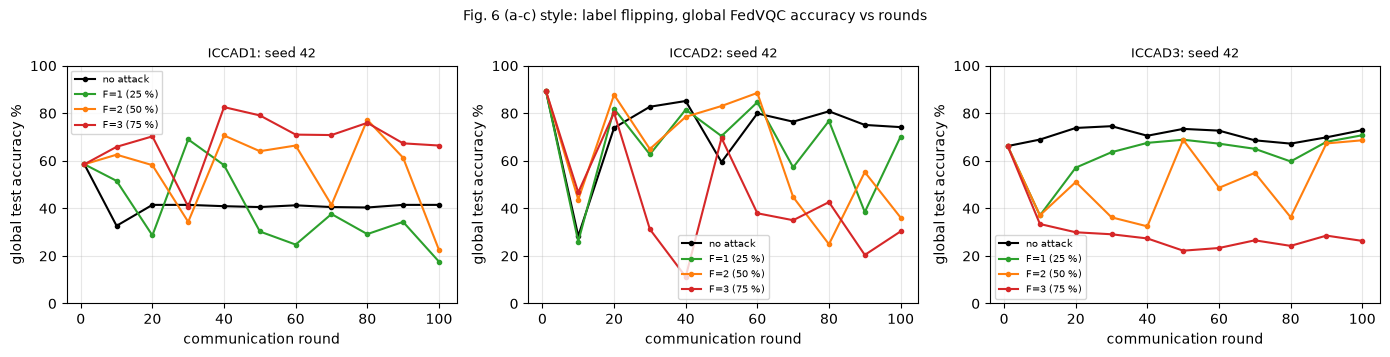

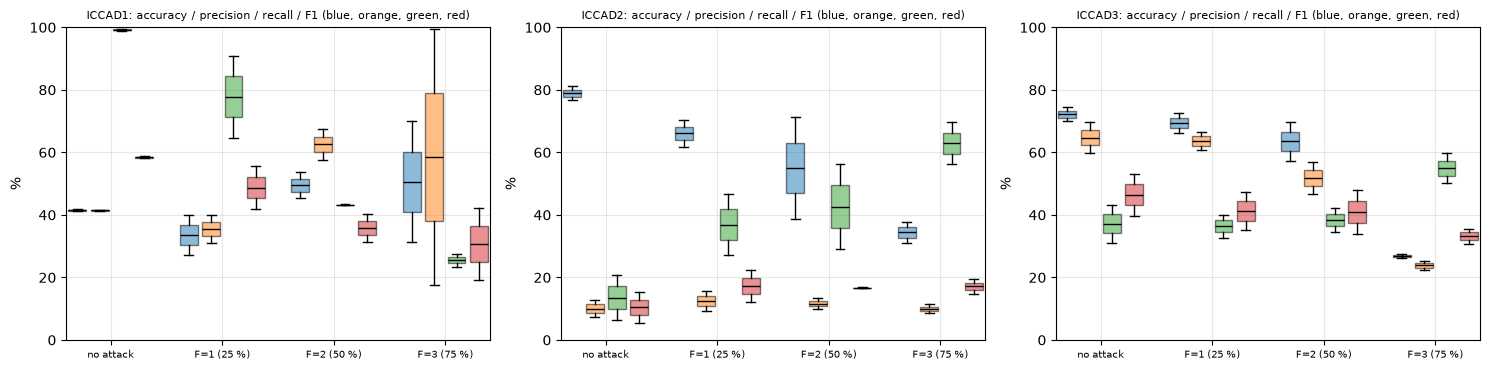

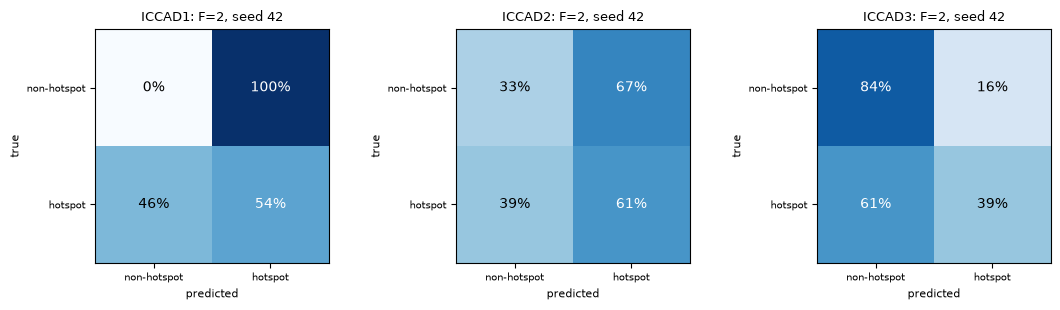

In [13]:
print(f"FedVQC with label flipping: F in {ATTACK_F} malicious houses out of {N_CLIENTS}, flip rate {FLIP_RATE}")
for F in ATTACK_F:
    for b in BENCHMARKS:
        for sd in SEEDS:
            do_run("q", b, f"F{F}", sd, F=F)
for r in RATE_SWEEP:                                  # full run only: F = 2 houses that flip only a fraction of their labels
    for b in BENCHMARKS:
        do_run("q", b, f"F2 q={r}", SEEDS[0], F=2, rate=r)

SCEN = ["clean"] + [f"F{F}" for F in ATTACK_F]
LBL = {"clean": "no attack", "F1": "F=1 (25 %)", "F2": "F=2 (50 %)", "F3": "F=3 (75 %)"}
for key, name in (("acc", "accuracy %"), ("f1", "F1 (hotspot) %"), ("tpr", "recall / TPR %"), ("fpr", "FPR %")):
    print(name)
    display(pd.DataFrame({LBL[s]: {b: pm("q", b, s, key) for b in BENCHMARKS} for s in SCEN}))
if RATE_SWEEP:
    print("accuracy % of F = 2 houses that flip only a fraction q of their labels (seed", SEEDS[0], ")")
    display(pd.DataFrame({f"q={r}": {b: f"{100*final_metrics(RES[('q', b, f'F2 q={r}', SEEDS[0])])['acc']:.1f}" for b in BENCHMARKS} for r in RATE_SWEEP}
                         ).assign(**{"q=1.0": {b: f"{100*final_metrics(RES[('q', b, 'F2', SEEDS[0])])['acc']:.1f}" for b in BENCHMARKS}}))

# ---- cf. paper Fig. 6 (a-c): global test accuracy during training for increasing attack proportions ----
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, b in zip(axs, BENCHMARKS):
    for s, col in zip(SCEN, ("k", "tab:green", "tab:orange", "tab:red")):
        o = RES[("q", b, s, SEEDS[0])]
        ax.plot([h["round"] for h in o["hist"]], [100 * h["acc"] for h in o["hist"]], "-o", ms=3, color=col, label=LBL[s])
    ax.set_xlabel("communication round"); ax.set_ylabel("global test accuracy %"); ax.set_ylim(0, 100); ax.set_title(f"{b}: seed {SEEDS[0]}", fontsize=9); ax.legend(fontsize=7)
plt.suptitle("Fig. 6 (a-c) style: label flipping, global FedVQC accuracy vs rounds", fontsize=10); plt.tight_layout(); plt.show()

# ---- Fig. 6 (d-f): box plots over the seeds of accuracy / precision / recall / F1 per attack proportion ----
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, b in zip(axs, BENCHMARKS):
    keys = ("acc", "prec", "rec", "f1"); cols = ("tab:blue", "tab:orange", "tab:green", "tab:red")
    for si, s in enumerate(SCEN):
        for ki, k in enumerate(keys):
            vals = [100 * final_metrics(RES[("q", b, s, sd)])[k] for sd in SEEDS]
            pos = si * 5 + ki
            ax.boxplot([vals], positions=[pos], widths=0.8, patch_artist=True, boxprops=dict(facecolor=cols[ki], alpha=0.5), medianprops=dict(color="k"))
    ax.set_xticks([si * 5 + 1.5 for si in range(len(SCEN))]); ax.set_xticklabels([LBL[s] for s in SCEN], fontsize=7); ax.set_ylim(0, 100); ax.set_ylabel("%")
    ax.set_title(f"{b}: accuracy / precision / recall / F1 (blue, orange, green, red)", fontsize=8)
plt.tight_layout(); plt.show()

# ---- Fig. 6 (g-i): confusion matrices with 50 % malicious houses (F = 2) ----
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, b in zip(axs, BENCHMARKS):
    draw_conf(ax, RES[("q", b, "F2", SEEDS[0])], f"{b}: F=2, seed {SEEDS[0]}")
plt.tight_layout(); plt.show()


## 6. The clustering defence (paper Section IV-D, Fig. 7)

Every round the server takes the four client updates (`theta_local - theta_global`), projects them to 2 principal components, computes the pairwise Euclidean distances and bipartitions the houses around the two most distant ones.
If the distance between the two seeds exceeds the fixed threshold epsilon (calibrated on the clean runs), the minority cluster (in a 2-2 tie: the denser one) is declared malicious and left out of the average.
Two variants are evaluated: the paper's **per-round** rule and our **extension with memory** (the normalised updates are smoothed over the rounds with an exponential moving average, because one round of 3 local steps is very noisy).
The detection tables replay the detector on the logged updates of the *undefended* runs of all seeds (monitoring mode), so they measure how well bad updates can be recognised; the last table runs the defence in the loop (extension variant, first seed) and shows what it does to the accuracy.

threshold eps (90th percentile of the clean-run statistic):


,paper: per round,extension: with memory
ICCAD1,1.738,1.805
ICCAD2,1.842,1.811
ICCAD3,1.711,1.789


share of clean rounds in which the detector flags somebody (false alarms, %):


,paper: per round,extension: with memory
ICCAD1,10.0,10.0
ICCAD2,10.0,10.0
ICCAD3,10.0,10.0


,benchmark,malicious,paper: per round: malicious flagged %,paper: per round: honest flagged %,extension: with memory: malicious flagged %,extension: with memory: honest flagged %
0,ICCAD1,F=1,26,8,38,7
1,ICCAD1,F=2,25,26,36,35
2,ICCAD1,F=3,8,24,5,50
3,ICCAD2,F=1,5,4,9,9
4,ICCAD2,F=2,5,4,11,6
5,ICCAD2,F=3,4,6,3,16
6,ICCAD3,F=1,24,10,48,3
7,ICCAD3,F=2,21,16,42,12
8,ICCAD3,F=3,9,26,0,65


...

  [q] ICCAD3 F2+def     seed 42  malicious=(0, 3)  acc  56.3  F1  40.4  TPR  42.9  FPR  36.8   (257 s)


  [q] ICCAD1 F3+def     seed 42  malicious=(0, 1, 3)  acc  66.9  F1  31.9  TPR  20.4  FPR   0.2   (128 s)


  [q] ICCAD2 F3+def     seed 42  malicious=(0, 1, 3)  acc  44.1  F1  14.9  TPR  45.5  FPR  56.1   (128 s)


  [q] ICCAD3 F3+def     seed 42  malicious=(0, 1, 3)  acc  24.8  F1  24.1  TPR  36.0  FPR  80.9   (222 s)


,benchmark,malicious,flagged in the loop: malicious %,flagged in the loop: honest %,accuracy % no attack (seed 42),"accuracy % attack, no defence",accuracy % attack + defence
0,ICCAD1,F=1,33,2,41.1,27.0,41.2
1,ICCAD1,F=2,41,2,41.1,53.7,27.6
2,ICCAD1,F=3,11,41,41.1,69.9,66.9
3,ICCAD2,F=1,0,1,76.7,61.8,59.0
4,ICCAD2,F=2,3,2,76.7,38.8,65.2
5,ICCAD2,F=3,2,6,76.7,31.1,44.1
6,ICCAD3,F=1,45,1,70.0,66.1,74.0
7,ICCAD3,F=2,10,2,70.0,57.4,56.3
8,ICCAD3,F=3,3,31,70.0,26.4,24.8


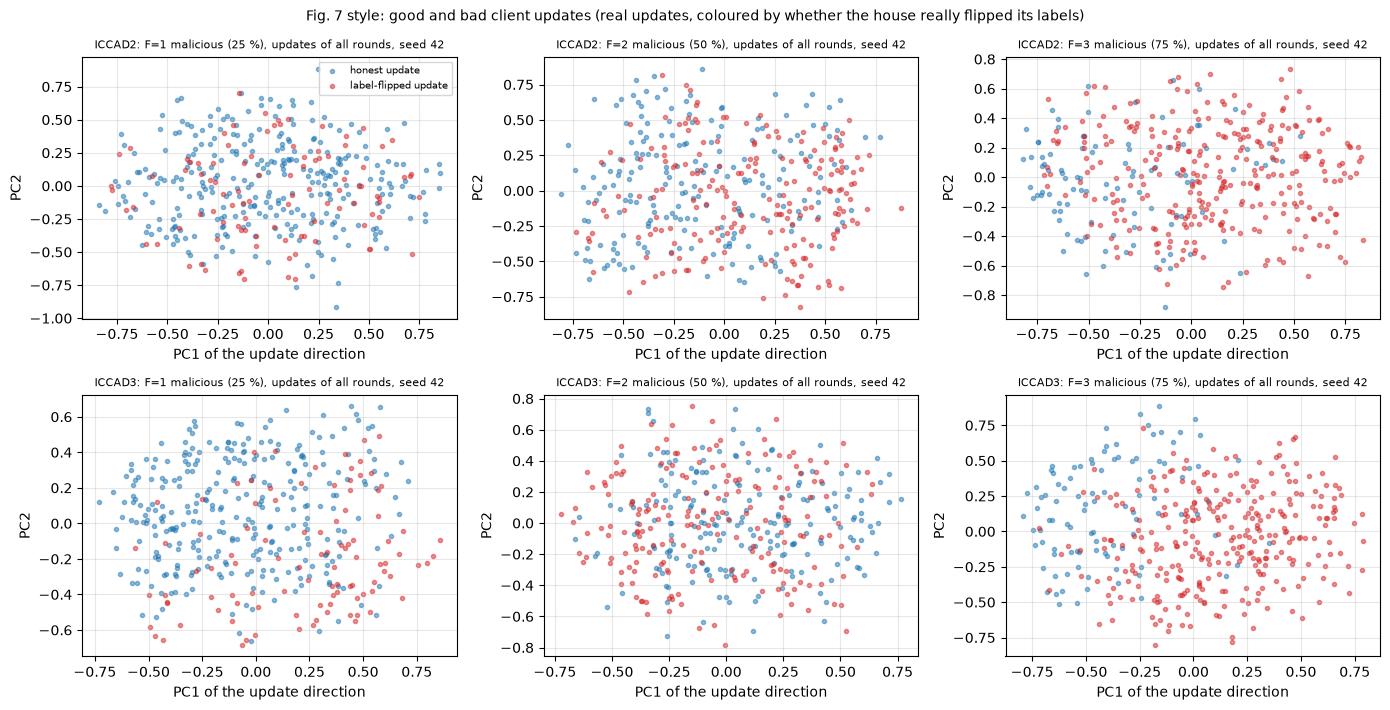

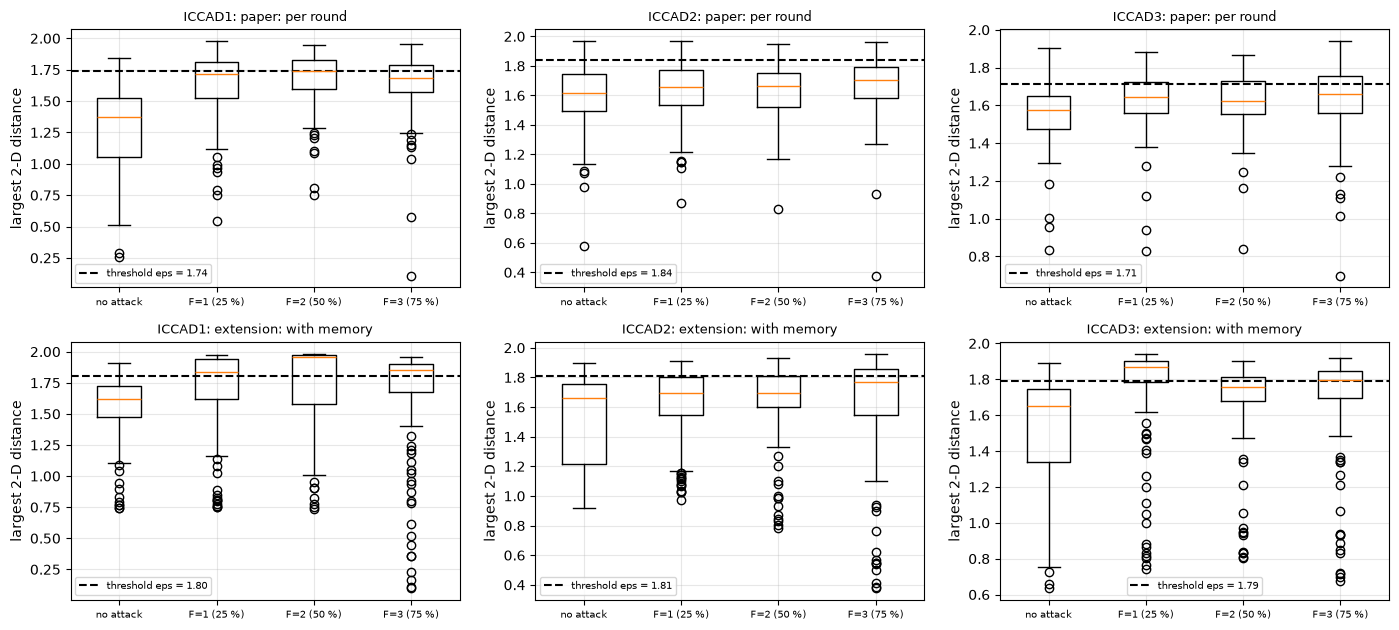

,benchmark,median distance(malicious pair) / distance(honest pair)
0,ICCAD1,0.97
1,ICCAD2,0.96
2,ICCAD3,0.95


In [14]:
VARIANTS = {"paper: per round": 0.0, "extension: with memory": MEM_BETA}      # beta of the exponential moving average over the rounds
MEM = "extension: with memory"

# ---- threshold calibration (CHOICE): the paper uses 'a fixed threshold' without a value.  We take, per benchmark and variant, the 90th percentile of the
#      statistic (largest 2-D distance between two normalised client updates) over all rounds of the attack-free runs: about one clean round in ten raises an alarm.
for b in BENCHMARKS:
    for v, beta in VARIANTS.items():
        EPS[(b, v)] = float(np.quantile(np.concatenate([replay(RES[("q", b, "clean", s)]["updates"], beta, np.inf)[0] for s in SEEDS]), 0.9))
print("threshold eps (90th percentile of the clean-run statistic):")
display(pd.DataFrame({v: {b: round(EPS[(b, v)], 3) for b in BENCHMARKS} for v in VARIANTS}))

# ---- (a) detection quality in monitoring mode: the detector is replayed on the logged updates of the UNDEFENDED runs (all seeds) ----
def detection(kind_scen_fmt, seeds, v, b, F):
    rec, fal = [], []
    for sd in seeds:
        o = RES[("q", b, kind_scen_fmt.format(F=F), sd)]
        m = np.zeros(N_CLIENTS, bool); m[list(o["malicious"])] = True
        if o["flagged"].any() or kind_scen_fmt.endswith("+def"):
            fl = o["flagged"]                                        # defended run: the flags that were really used
        else:
            fl = replay(o["updates"], VARIANTS[v], EPS[(b, v)])[1]    # monitoring mode on an undefended run
        rec.append(fl[:, m].mean()); fal.append(fl[:, ~m].mean())
    return 100 * np.mean(rec), 100 * np.mean(fal)

# clean runs: how often does the detector raise a (false) alarm when nobody is malicious?
fa = {v: {b: 100 * np.mean([replay(RES[("q", b, "clean", s)]["updates"], beta, EPS[(b, v)])[1].any(axis=1).mean() for s in SEEDS]) for b in BENCHMARKS} for v, beta in VARIANTS.items()}
print("share of clean rounds in which the detector flags somebody (false alarms, %):")
display(pd.DataFrame(fa).round(0))

det = []
for b in BENCHMARKS:
    for F in ATTACK_F:
        row = dict(benchmark=b, malicious=f"F={F}")
        for v in VARIANTS:
            r_, f_ = detection("F{F}", SEEDS, v, b, F)
            row[f"{v}: malicious flagged %"] = round(r_); row[f"{v}: honest flagged %"] = round(f_)
        det.append(row)
DET = pd.DataFrame(det); display(DET)

# ---- (b) the defence in the loop: flagged houses are left out of FedAvg (extension variant with memory, first seed only) ----
print(f"FedVQC with the defence in the loop ({MEM}), seeds {DEF_SEEDS}")
for F in ATTACK_F:
    for b in BENCHMARKS:
        for sd in DEF_SEEDS:
            do_run("q", b, f"F{F}+def", sd, F=F, defence=(MEM_BETA, EPS[(b, MEM)]))
rows = []
for b in BENCHMARKS:
    for F in ATTACK_F:
        r_, f_ = detection("F{F}+def", DEF_SEEDS, MEM, b, F)
        s0 = DEF_SEEDS[0]
        rows.append({"benchmark": b, "malicious": f"F={F}", "flagged in the loop: malicious %": round(r_), "flagged in the loop: honest %": round(f_),
                     f"accuracy % no attack (seed {s0})": round(100 * final_metrics(RES[("q", b, "clean", s0)])["acc"], 1),
                     f"accuracy % attack, no defence": round(100 * final_metrics(RES[("q", b, f"F{F}", s0)])["acc"], 1),
                     f"accuracy % attack + defence": round(100 * final_metrics(RES[("q", b, f"F{F}+def", s0)])["acc"], 1)})
DEFTAB = pd.DataFrame(rows); display(DEFTAB)

# ---- cf. paper Fig. 7: the client updates (unit-norm directions) in the plane of their first two principal components, all rounds pooled ----
fig, axs = plt.subplots(2, 3, figsize=(14, 7.2))
for r_, b in enumerate(("ICCAD2", "ICCAD3")):
    for c_, F in enumerate(ATTACK_F):
        o = RES[("q", b, f"F{F}", SEEDS[0])]; U = o["updates"]                     # (rounds, clients, params)
        U = U / (np.linalg.norm(U, axis=2, keepdims=True) + 1e-12)
        Z = PCA(n_components=2).fit_transform(U.reshape(-1, U.shape[2])).reshape(U.shape[0], U.shape[1], 2)
        m = np.zeros(N_CLIENTS, bool); m[list(o["malicious"])] = True
        ax = axs[r_, c_]
        ax.scatter(Z[:, ~m, 0].ravel(), Z[:, ~m, 1].ravel(), s=9, c="tab:blue", alpha=0.5, label="honest update")
        ax.scatter(Z[:, m, 0].ravel(), Z[:, m, 1].ravel(), s=9, c="tab:red", alpha=0.5, label="label-flipped update")
        ax.set_title(f"{b}: F={F} malicious ({100*F//N_CLIENTS} %), updates of all rounds, seed {SEEDS[0]}", fontsize=8); ax.set_xlabel("PC1 of the update direction"); ax.set_ylabel("PC2")
        if r_ == 0 and c_ == 0: ax.legend(fontsize=7)
plt.suptitle("Fig. 7 style: good and bad client updates (real updates, coloured by whether the house really flipped its labels)", fontsize=10)
plt.tight_layout(); plt.show()

# ---- the statistic of the detector per round: clean vs attacked runs and the threshold ----
fig, axs = plt.subplots(2, 3, figsize=(14, 6.4))
for r_, (v, beta) in enumerate(VARIANTS.items()):
    for ax, b in zip(axs[r_], BENCHMARKS):
        vals = [replay(RES[("q", b, s, SEEDS[0])]["updates"], beta, np.inf)[0] for s in SCEN]
        ax.boxplot(vals, tick_labels=[LBL[s] for s in SCEN]); ax.axhline(EPS[(b, v)], color="k", ls="--", label=f"threshold eps = {EPS[(b, v)]:.2f}")
        ax.set_ylabel("largest 2-D distance"); ax.set_title(f"{b}: {v}", fontsize=9); ax.legend(fontsize=7); ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

# ---- paper: 'the malicious gradients are more similar among themselves, i.e. denser clusters' -> distance inside the malicious pair / distance inside the honest pair (F = 2, normalised updates) ----
dens = []
for b in BENCHMARKS:
    rr = []
    for sd in SEEDS:
        o = RES[("q", b, "F2", sd)]; U = o["updates"]; U = U / (np.linalg.norm(U, axis=2, keepdims=True) + 1e-12)
        m = list(o["malicious"]); h = [c for c in range(N_CLIENTS) if c not in m]
        rr.append(np.median(np.linalg.norm(U[:, m[0]] - U[:, m[1]], axis=1) / (np.linalg.norm(U[:, h[0]] - U[:, h[1]], axis=1) + 1e-12)))
    dens.append(dict(benchmark=b, **{"median distance(malicious pair) / distance(honest pair)": round(float(np.mean(rr)), 2)}))
DENS = pd.DataFrame(dens); display(DENS)


## 7. Classical twin and centralised baselines (not in the paper)

The same federation, partition, attack and number of rounds with a classical **logistic regression** (513 parameters) on the identical unit-norm PCA vectors, plus centralised RandomForest and SVC (rbf) trained on the clean pooled training clips. The quantum circuit has 42 parameters, so it is a much smaller model.

FedLogReg (logistic regression, 513 parameters; 257 for Benchmark1) under the same attacks


  [c] ICCAD1 clean      seed 42  malicious=()  acc  41.5  F1  58.6  TPR 100.0  FPR 100.0   (2 s)


  [c] ICCAD1 clean      seed 43  malicious=()  acc  41.5  F1  58.6  TPR 100.0  FPR 100.0   (3 s)


  [c] ICCAD2 clean      seed 42  malicious=()  acc  92.7  F1  53.2  TPR  39.7  FPR   0.9   (5 s)


  [c] ICCAD2 clean      seed 43  malicious=()  acc  92.0  F1  47.8  TPR  34.9  FPR   1.1   (3 s)


...

,ICCAD1,ICCAD2,ICCAD3
"RandomForest (200 trees, balanced)",acc 58.5 | F1 0.0 | TPR 0.0 | FPR 0.0 (13 s),acc 89.3 | F1 0.0 | TPR 0.0 | FPR 0.0 (61 s),acc 66.2 | F1 0.0 | TPR 0.0 | FPR 0.0 (182 s)
"SVC rbf (C=1, balanced)",acc 40.9 | F1 58.1 | TPR 98.7 | FPR 100.0 (1 s),acc 89.3 | F1 0.0 | TPR 0.0 | FPR 0.0 (50 s),acc 74.7 | F1 40.1 | TPR 25.1 | FPR 0.0 (170 s)
RandomForest on 1600 raw pixels,acc 73.0 | F1 75.3 | TPR 99.1 | FPR 45.5 (9 s),acc 89.3 | F1 0.0 | TPR 0.0 | FPR 0.0 (24 s),acc 66.2 | F1 0.0 | TPR 0.0 | FPR 0.0 (52 s)


accuracy % (mean +- std over seeds)


no attack     F=1 (25 %)  \
FedVQC (quantum)           ICCAD1   41.5 +-  0.4   33.5 +-  6.4   
                           ICCAD2   78.9 +-  2.2   66.1 +-  4.3   
                           ICCAD3   72.2 +-  2.2   69.3 +-  3.2   
FedLogReg (classical twin) ICCAD1   41.5 +-  0.0   40.0 +- 14.2   
                           ICCAD2   92.4 +-  0.4   88.0 +-  3.9   
                           ICCAD3   83.7 +-  0.9   78.0 +-  3.2   

                                      F=2 (50 %)     F=3 (75 %)  
FedVQC (quantum)           ICCAD1   49.5 +-  4.2   50.6 +- 19.4  
                           ICCAD2   55.0 +- 16.2   34.4 +-  3.3  
                           ICCAD3   63.6 +-  6.2   26.9 +-  0.6  
FedLogReg (classical twin) ICCAD1   27.9 +-  7.6   59.4 +-  0.8  
                           ICCAD2   66.0 +- 17.7    9.8 +-  1.5  
                           ICCAD3   60.3 +- 22.8   21.1 +-  0.6

F1 (hotspot) % (mean +- std over seeds)


no attack     F=1 (25 %)  \
FedVQC (quantum)           ICCAD1   58.5 +-  0.2   48.7 +-  6.8   
                           ICCAD2   10.4 +-  5.0   17.3 +-  5.1   
                           ICCAD3   46.5 +-  6.7   41.3 +-  6.2   
FedLogReg (classical twin) ICCAD1   58.6 +-  0.0   51.7 +- 12.6   
                           ICCAD2   50.5 +-  2.7   47.5 +-  1.5   
                           ICCAD3   68.7 +-  2.3   60.4 +-  4.1   

                                      F=2 (50 %)     F=3 (75 %)  
FedVQC (quantum)           ICCAD1   35.8 +-  4.4   30.8 +- 11.5  
                           ICCAD2   16.7 +-  0.1   17.1 +-  2.3  
                           ICCAD3   40.9 +-  7.1   33.2 +-  2.4  
FedLogReg (classical twin) ICCAD1   40.0 +-  7.4   12.9 +-  3.5  
                           ICCAD2   29.0 +-  9.1   12.3 +-  0.8  
                           ICCAD3   52.8 +- 18.6   32.1 +-  1.5

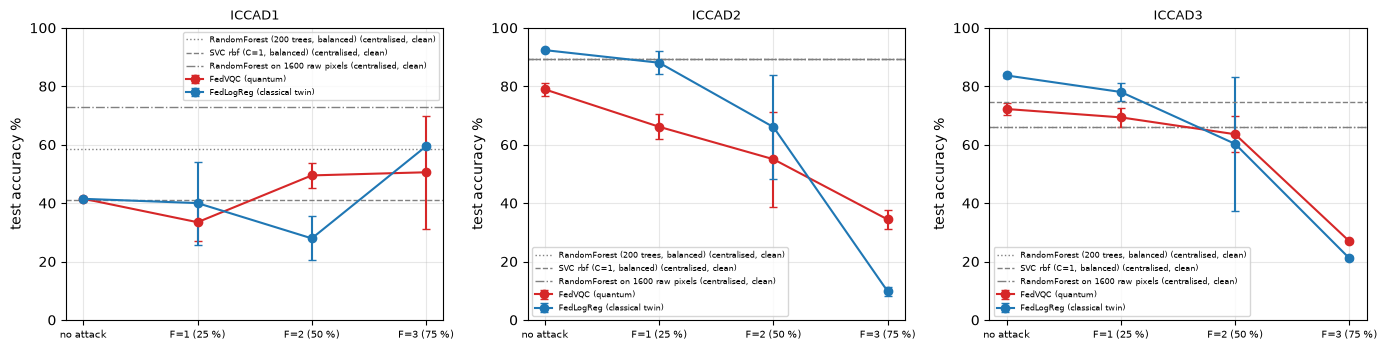

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# ---- (a) the classical federated twin: same partition, same attack, same rounds / local steps, same unit-norm PCA amplitude vectors as input ----
print("FedLogReg (logistic regression, 513 parameters; 257 for Benchmark1) under the same attacks")
for s_ in SCEN:
    F = 0 if s_ == "clean" else int(s_[1:])
    for b in BENCHMARKS:
        for sd in SEEDS:
            do_run("c", b, s_, sd, F=F)

# ---- (b) centralised classical baselines on the identical inputs (clean labels, all training clips pooled), plus one on all 1600 raw pixels ----
t0 = time.time(); CENT = {}
NAMES = ["RandomForest (200 trees, balanced)", "SVC rbf (C=1, balanced)", "RandomForest on 1600 raw pixels"]
for b in BENCHMARKS:
    d = DATA[b]
    raw_tr, raw_te = RAW[b]["train"][0].reshape(len(d["ytr"]), -1) / 255.0, RAW[b]["test"][0].reshape(len(d["yte"]), -1) / 255.0
    for name, clf, Xtr_, Xte_ in ((NAMES[0], RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=SEED, n_jobs=2), d["Atr"], d["Ate"]),
                                  (NAMES[1], SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED), d["Atr"], d["Ate"]),
                                  (NAMES[2], RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=SEED, n_jobs=2), raw_tr, raw_te)):
        tt0 = time.time(); clf.fit(Xtr_, d["ytr"]); pred = clf.predict(Xte_)
        m = metrics_from_p(pred.astype(float), d["yte"]); m["time"] = time.time() - tt0; CENT[(b, name)] = m
print(f"centralised baselines done in {time.time()-t0:.0f} s")
display(pd.DataFrame({f"{b}": {name: f"acc {100*CENT[(b, name)]['acc']:.1f} | F1 {100*CENT[(b, name)]['f1']:.1f} | TPR {100*CENT[(b, name)]['tpr']:.1f} | FPR {100*CENT[(b, name)]['fpr']:.1f} ({CENT[(b, name)]['time']:.0f} s)"
                      for name in NAMES} for b in BENCHMARKS}))
# ---- (c) quantum vs classical, test accuracy and hotspot F1 under label flipping ----
for key, name in (("acc", "accuracy %"), ("f1", "F1 (hotspot) %")):
    print(name, "(mean +- std over seeds)")
    rows = {}
    for kind in ("q", "c"):
        for b in BENCHMARKS:
            rows[(KINDS[kind], b)] = {LBL[s_]: pm(kind, b, s_, key) for s_ in SCEN}
    display(pd.DataFrame(rows).T)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, b in zip(axs, BENCHMARKS):
    for kind, col in (("q", "tab:red"), ("c", "tab:blue")):
        mu = [agg(kind, b, s_, "acc")[0] for s_ in SCEN]; sd_ = [agg(kind, b, s_, "acc")[1] for s_ in SCEN]
        ax.errorbar(range(len(SCEN)), mu, yerr=sd_, fmt="-o", color=col, capsize=3, label=KINDS[kind])
    for name, ls in ((NAMES[0], ":"), (NAMES[1], "--"), (NAMES[2], "-.")):
        ax.axhline(100 * CENT[(b, name)]["acc"], color="gray", ls=ls, lw=1, label=name + " (centralised, clean)")
    ax.set_xticks(range(len(SCEN))); ax.set_xticklabels([LBL[s_] for s_ in SCEN], fontsize=7); ax.set_ylim(0, 100); ax.set_ylabel("test accuracy %"); ax.set_title(b, fontsize=9); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()


## 8. Side-by-side comparison with the paper, claim by claim

Tolerance: 2 points (accuracy, F-score, rates). "reproduced" = within tolerance (or, for qualitative claims, the stated criterion holds); "not reached" / "exceeded" = outside tolerance on the worse / better side for the model;
for attack claims "not reached" means the degradation reported by the paper was **not** observed (the model was more robust), "exceeded" means it degraded more.

In [16]:
TOL = 2.0                              # accuracy / rate points (the brief's 2-point rule; F1 is compared in percent as well)
def verdict(nb, paper, higher_is_better=True, tol=TOL):
    if nb is None or np.isnan(nb): return "cannot be checked"
    if abs(nb - paper) <= tol: return "reproduced"
    return "exceeded" if (nb > paper) == higher_is_better else "not reached"

rows = []
def add(claim, paper_txt, nb_val, v, unit=" %"):
    rows.append({"Claim (paper section / figure)": claim, "Paper": paper_txt, "This notebook": ("n/a" if nb_val is None else f"{nb_val:.1f}{unit}"), "Verdict": v})

A = lambda b, s, k, kind="q": agg(kind, b, s, k)[0]
# --- no attack (Section IV-B, Fig. 5) ---
add("no attack, Benchmark1: mean test accuracy (Fig. 5g; not stated in the text)", "not stated", A("ICCAD1", "clean", "acc"), "cannot be checked")
add("no attack, Benchmark2: mean test accuracy (text, Fig. 5h)", "93 %", A("ICCAD2", "clean", "acc"), verdict(A("ICCAD2", "clean", "acc"), 93))
add("no attack, Benchmark3: mean test accuracy (text, Fig. 5i)", "87 %", A("ICCAD3", "clean", "acc"), verdict(A("ICCAD3", "clean", "acc"), 87))
for b, pf in zip(BENCHMARKS, (88, 94, 86)):
    add(f"no attack, {b}: average F-score (text, Fig. 5g-i; support-weighted F1 of the two classes)", f"about {pf} %", A(b, "clean", "wf1"), verdict(A(b, "clean", "wf1"), pf))
for b in BENCHMARKS:
    t = A(b, "clean", "tpr")
    add(f"no attack, {b}: true-positive rate (text: between 90 % and 95 %)", "90-95 %", t, "reproduced" if 88 <= t <= 97 else ("exceeded" if t > 97 else "not reached"))
for b, pf in zip(BENCHMARKS, (15, 1, 33)):
    add(f"no attack, {b}: false-positive rate (text, Fig. 5j-l)", f"about {pf} %", A(b, "clean", "fpr"), verdict(A(b, "clean", "fpr"), pf, higher_is_better=False))
for b in BENCHMARKS:
    o = RES[("q", b, "clean", SEEDS[0])]["hist"][-1]; best_local = min(o["local_loss"])
    add(f"no attack, {b}: global model has a lower test loss than every local house (text, Fig. 5d-f; seed {SEEDS[0]}, last evaluation)", "global < all locals", None,
        "reproduced" if o["loss"] < best_local else "not reached")
    rows[-1]["This notebook"] = f"global {o['loss']:.3f} vs best local {best_local:.3f}"
# --- label flipping (Section IV-C, Fig. 6) ---
for b in BENCHMARKS:
    drop = A(b, "clean", "acc") - A(b, "F1", "acc")
    add(f"F=1 (25 % malicious), {b}: 'performance does not decrease significantly' (drop in accuracy, <= 5 points counted as reproduced)", "no significant drop", drop, "reproduced" if drop <= 5 else "not reached", unit=" pts")
for b, pf in zip(BENCHMARKS, (72, 60, 60)):
    add(f"F=2 (50 % malicious), {b}: test accuracy (text, Fig. 6a-c)", f"{pf} %", A(b, "F2", "acc"), verdict(A(b, "F2", "acc"), pf, higher_is_better=False))
for b in BENCHMARKS:
    a3 = A(b, "F3", "acc")
    add(f"F=3 (75 % malicious), {b}: accuracy collapses below 20 % (text, 'more than 50 % of the data')", "< 20 %", a3, "reproduced" if a3 < 22 else "not reached")
# --- defence (Section IV-D, Fig. 7); detection measured in monitoring mode on the undefended runs, all seeds ---
for v, tag in (("paper: per round", "paper rule, per round"), ("extension: with memory", "extension with memory")):
    for b in BENCHMARKS:
        r = DET[(DET.benchmark == b) & (DET.malicious == "F=1")].iloc[0]; rec, fal = r[f"{v}: malicious flagged %"], r[f"{v}: honest flagged %"]
        add(f"defence ({tag}), {b}, 25 % malicious: bad updates separated from good ones (malicious flagged >= 90 % and honest flagged <= 10 % of client-rounds)", "identified", float(rec),
            "reproduced" if (rec >= 90 and fal <= 10) else "not reached")
        rows[-1]["This notebook"] = f"flagged {rec:.0f} % of bad / {fal:.0f} % of good"
for v, tag in (("paper: per round", "paper rule, per round"), ("extension: with memory", "extension with memory")):
    for b in BENCHMARKS:
        r = DET[(DET.benchmark == b) & (DET.malicious == "F=3")].iloc[0]; rec, fal = r[f"{v}: malicious flagged %"], r[f"{v}: honest flagged %"]
        add(f"defence ({tag}), {b}, 75 % malicious: fails when the malicious houses are the majority (malicious flagged < 50 %)", "fails beyond 50 %", float(rec),
            "reproduced" if rec < 50 else "not reached")
        rows[-1]["This notebook"] = f"flagged {rec:.0f} % of bad / {fal:.0f} % of good"
for _, r in DENS.iterrows():
    v = list(r.values)[1]
    add(f"malicious updates are more similar to each other than honest ones (ratio < 1), {r['benchmark']}, F=2", "denser clusters", None, "reproduced" if v < 1 else "not reached")
    rows[-1]["This notebook"] = f"ratio {v}"

CMP = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(CMP)
print(CMP["Verdict"].value_counts().to_string())


,Claim (paper section / figure),Paper,This notebook,Verdict
0,"no attack, Benchmark1: mean test accuracy (Fig. 5g; not stated in the text)",not stated,41.5 %,cannot be checked
1,"no attack, Benchmark2: mean test accuracy (text, Fig. 5h)",93 %,78.9 %,not reached
2,"no attack, Benchmark3: mean test accuracy (text, Fig. 5i)",87 %,72.2 %,not reached
3,"no attack, ICCAD1: average F-score (text, Fig. 5g-i; support-weighted F1 of the two classes)",about 88 %,24.9 %,not reached
4,"no attack, ICCAD2: average F-score (text, Fig. 5g-i; support-weighted F1 of the two classes)",about 94 %,79.6 %,not reached
5,"no attack, ICCAD3: average F-score (text, Fig. 5g-i; support-weighted F1 of the two classes)",about 86 %,69.4 %,not reached
6,"no attack, ICCAD1: true-positive rate (text: between 90 % and 95 %)",90-95 %,99.3 %,exceeded
7,"no attack, ICCAD2: true-positive rate (text: between 90 % and 95 %)",90-95 %,13.6 %,not reached
8,"no attack, ICCAD3: true-positive rate (text: between 90 % and 95 %)",90-95 %,37.2 %,not reached
9,"no attack, ICCAD1: false-positive rate (text, Fig. 5j-l)",about 15 %,99.4 %,not reached


Verdict
not reached          23
reproduced           11
exceeded              4
cannot be checked     1


## 9. Reading the paper critically

*The numbers quoted here come from the stored full run (`FAST_MODE = False`: 100 rounds, two seeds, 117.8 minutes on a heavily shared CPU, including a 9-minute download). The `FAST_MODE` run (20 rounds, one seed, 17 minutes) shows the same picture with larger noise. With two seeds the "+-" values are only a rough indication.*

**What the re-run supports.**
* **The data and Table I.** The public ICCAD-2012 mirror reproduces all 12 class counts of Table I exactly, and 512 PCA components keep 99.0 - 99.3 % of the variance (Benchmark1: 256 components keep 100 % because it has only 439 training clips).
* **Label flipping hurts, in proportion to the share of malicious houses, and a majority of attackers is catastrophic.** On Benchmark3 the FedVQC accuracy goes 72.2 % (no attack) -> 69.3 % (F=1, 25 %) -> 63.6 % (F=2, 50 %) -> 26.9 % (F=3, 75 %); on Benchmark2 78.9 -> 66.1 -> 55.0 -> 34.4 %. The 75 % case collapses to the accuracy of a model that is wrong most of the time, qualitatively as in the paper ("below 20 %"), but not as far (26.9 / 34.4 % against < 20 %). F=2 gives 63.6 % (Benchmark3, paper 60 %) and 55.0 % (Benchmark2, paper 60 %): within a few points of the paper's numbers, but with a clean accuracy that is far below the paper's, so the size of the drop is smaller.
* **The classical twin shows the same pattern and reproduces the paper's clean numbers.** A federated logistic regression on the identical amplitude vectors reaches 92.4 % (Benchmark2, paper 93 %) and 83.7 % (Benchmark3, paper 87 %) with false-positive rates around 1 % (paper: about 1 % for Benchmark2) and degrades 83.7 -> 78.0 -> 60.3 -> 21.1 % with 0 - 3 malicious houses. So the data, the partition and the attack are faithful enough to reproduce the paper's numbers; the quantum model is what falls short.
* **Beyond 50 % the defence fails** (qualitative claim of Section IV-D): at F=3 the detector flags at most 9 % of the malicious client-rounds (paper rule) and flags honest houses in up to 26 % of the rounds (65 % with memory).

**What it does not support, and why each number needs care.**
* **The quantum model does not reach the paper's clean performance.** 78.9 / 72.2 % accuracy (Benchmarks 2 / 3) against 93 / 87 %, hotspot recall 13.6 / 37.2 % against 90-95 %. Reasons we can name: (i) a 42-parameter circuit whose output is a quadratic form `x^T M(theta) x` of a unit vector with `M` a rotated rank-256 projector is a very small model next to a 513-parameter linear classifier; (ii) the paper does not give depth, local epochs, optimiser or learning rate, and our 3 local Adam steps per round are a guess (a larger budget was out of reach on this CPU: one 100-round run takes about two minutes); (iii) deeper circuits (3 layers) were not better in short pilots. Whether the authors' own VQC differs in an important detail (single-qubit gates, readout, loss) cannot be told from the text.
* **Benchmark1 is not informative.** Both the quantum model and the classical twin predict "hotspot" for almost every test clip (TPR 99 - 100 %, FPR 99 - 100 %, accuracy 41.5 % = the test hotspot share). The training clips of the benchmark are 1200 x 1200 pixels and the test clips 1024 x 1024; after box-averaging to 40 x 40 they may not be on the same scale (we did not verify this), and the test set has 41.5 % hotspots against 22.6 % in training. We therefore do not read anything into the Benchmark1 attack numbers (they even move in the "wrong" direction, 41.5 -> 49.5 %, because an all-hotspot predictor gains accuracy when labels are scrambled).
* **Centralised baselines on the same unit-norm PCA vectors are poor too.** RandomForest and SVC predict (almost) only the majority class on Benchmarks 2 and 3 (accuracy 89.3 % and 66.2 - 74.7 %, hotspot recall 0 - 25 %), and a RandomForest on the raw 1600 pixels does the same; only the class-weighted logistic regression gets recall. High accuracy on imbalanced ICCAD data therefore says little: Benchmark2's test set is 89.3 % non-hotspot, and the paper's 93 % accuracy is only 3.7 points above the majority class.
* **The "F-score" is ambiguous.** A support-weighted F1 matches the paper's 94 % at 93 % accuracy best, but the paper does not define it; we report the weighted F1 and the hotspot F1 side by side.
* **The defence works much worse than the paper says.** With 3 local steps the client updates of different houses are almost orthogonal even when honest (cosine about 0.2), so the 2-D PCA of four updates is dominated by mini-batch noise. At 25 % malicious houses the paper's per-round rule flags 5 - 26 % of the bad client-rounds and 4 - 10 % of the good ones (threshold = 90th percentile of the clean statistic, i.e. 10 % false alarms by design); the smoothed variant (our extension) reaches 9 - 48 % for 3 - 9 % false alarms, still far from "identified". The malicious pair is only marginally closer to itself than the honest pair (distance ratio 0.95 - 0.97 against < 1 claimed). Running the extension in the loop does not give a reliable gain (single seed: e.g. Benchmark3 F=1 74.0 % with against 66.1 % without the defence, Benchmark2 F=1 59.0 against 61.8 %, Benchmark1 F=2 27.6 against 53.7 %), and the effect of one lucky or unlucky seed is as large as these differences. The paper gives no numbers for the defence, so only its qualitative claims can be checked; the result is likely sensitive to the unreported local training budget.
* **Attack strength depends on who the attackers are.** The malicious houses are a random subset; houses differ in size (12 - 40 % of the data) and F=2 results have standard deviations of 4 - 16 points over two seeds. The paper's box plots do not say what is varied across their repetitions.
* **The learning-rate and threshold choices are ours** (learning rate 0.1 from a validation split of Benchmark3 only; threshold from the clean runs), which a reader should treat as part of the method.

**Verdict count (section 8):** 11 claims reproduced, 4 exceeded, 23 not reached, 1 cannot be checked. Overall status: *partially reproduced* (the qualitative picture of label flipping is reproduced, the clean quantum performance and the defence are not).

## 10. Exercises

1. **Which houses are malicious?** The notebook takes the first `F` of one random permutation per seed. The houses differ strongly in size (12 % to 40 % of the data) and, in Benchmark1, in hotspot share. Repeat sections 5 and 6 with the *largest* and with the *smallest* houses as attackers (change `mal_set`). How much of the damage and of the detection quality depends on the data volume of the attacker?
2. **Partial flipping.** Use `FLIP_RATE = 0.25` and `0.5` for F = 1, 2 and 3 in all benchmarks (the full run only does F = 2). Where is the break-even between attackers and honest houses, and does the defence still see them?
3. **Threshold.** The defence threshold epsilon was set to the largest value seen in the clean runs. Replace it by the 95th percentile, or by a fixed value, and plot detection rate against false-alarm rate (an ROC curve over epsilon) for F = 1 and F = 2.
4. **Layers and read-out.** Change `N_LAYERS` to 1, 3 and 4 and `KAPPA` to 5 and 60. How much of the gap between the 42-parameter circuit and the 513-parameter logistic regression closes with depth, and what does it cost in simulation time?
5. **Beyond label flipping.** Let a malicious house send the *negated* update (a model-poisoning attack, scaled by 1x and 3x) instead of flipping labels. Does the clustering defence still separate it, and does FedAvg with plain averaging fail faster than under label flipping?